# Proyecto 2 — EEG con parpadeos reales (Eye-BCI): sacar el EOG con RLS

**Cómo leer este notebook:** igual que `proyecto1_eyebci.ipynb`. Cada sección empieza con un recuadro **"Dónde estamos"**. Antes de cada celda de código hay un bloque que dice qué hace y por qué. Debajo de cada gráfico o tabla hay un **"Qué mirar"** con lo que se ve y los números medidos.

---

## Qué pide el proyecto 2
Resolver el problema del proyecto 1 con **RLS** (o algoritmos basados en RLS), justificar cada decisión y **comparar RLS con LMS en condiciones parecidas**.

## De dónde partimos (proyecto 1)
Mismo dataset (Eye-BCI, sujeto 1, sesión 1), mismas señales y mismo esquema de cancelación:

- **`y(n)`:** un electrodo (`Fp1`, `Fp2`; `Pz` de control).
- **`x(n) = [HEO(n), HEO(n−1), HEO(n−2)]`:** la referencia, el único canal de EOG. FIR de `M = 3`.
- **`e(n) = y(n) − wᵀx(n)`:** el EEG estimado.

Lo que aprendimos y que condiciona este notebook:

| Resultado del proyecto 1 | Por qué importa para RLS |
|---|---|
| NLMS con δ chico no anda: `w(n)` salta de −6 a +5. | `HEO` tiene **52 veces menos potencia entre parpadeos**. NLMS normaliza por `‖x(n)‖²` y da pasos enormes justo cuando no hay nada que aprender. **RLS también normaliza** (por `R̂(n)`), así que puede caer en lo mismo. |
| Lo arregló `δ = 100·M·P_x`, `μ̃ = 0.3`: RRMSE 0.22 en el semi-sintético, ≈ Wiener en datos reales. | Es la vara contra la que se compara RLS. |
| Los coeficientes no llegan uno por uno a `w_o`, solo su suma (spread de `R` = 2685). | LMS/NLMS se frenan con el spread; **RLS no debería**. Hay que verificarlo. |

## Notación: `λ` cambia de significado
En el proyecto 1, `λ` era la fracción de parpadeo que llega a cada electrodo. En RLS, `λ` es el **factor de olvido** (como en las diapositivas de la materia). Para no mezclarlos, **acá la fracción de parpadeo se llama `β`**:

`y(n) = s(n) + β·η_EOG(n)`

## Índice
1. **Carga** (igual que el proyecto 1).
2. **Inspección**: un repaso corto y una pregunta nueva: ¿cada cuánto hay un parpadeo? Eso da la primera cota para `λ`.
3. **El filtro: RLS**: implementación y chequeos.
4. **Primera corrida y diagnóstico** sobre los datos reales.
5. **Semi-sintético**: elegir `λ` y `δ` con una respuesta conocida, y comparar con LMS.
6. **Datos reales**: RLS elegido contra NLMS, LMS y Wiener.
7. **Conclusiones**.

## §1. Carga

> **Dónde estamos:** la carga es la misma del proyecto 1 (§1 de `proyecto1_eyebci.ipynb`, ahí está explicado cada paso). Se repite acá para que el notebook corra solo.
>
> Pasos: parámetros → carga y alineación → chequeo de lo que se cargó.

### 1.1 Parámetros
Los mismos que en el proyecto 1:
- **`FS = 250`:** submuestreo de 1000 a 250 Hz. EEG y EOG están por debajo de ~40 Hz.
- **`T_INI, T_FIN = 2, 338`:** después de la tarea la señal se rompe; los primeros 2 s son el transitorio del pasa-altos.
- **`F_HP = 0.5`:** el mismo pasa-altos en todos los canales, a `y` y a `x` por igual.
- **`CANALES_MALOS`:** los 11 canales que el artículo declara defectuosos.

In [1]:
import json
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, lfilter, welch

mne.set_log_level("ERROR")

# Parámetros (los del proyecto 1)
RAIZ = "./datasets-presentacion-PASA/Sess01"
ARCHIVO = "ME011"           # Sujeto 01, sesión 1
FS_ORIG = 1000              # fs del .bdf [Hz]
FS = 250                    # Submuestreo 1000 -> 250 Hz
T_INI, T_FIN = 2, 338       # Ventana útil [s]
F_HP = 0.5                  # Pasa-altos [Hz], igual en todos los canales
CANAL_EOG = "HEO"
CANALES_MALOS = ["PO3", "F1", "POz", "Oz", "F3", "O2", "P8", "PO7", "FC3", "P7", "P4"]  # Defectuosos según el artículo

### 1.2 Carga y alineación
`cargar()` es la del proyecto 1: pasa-altos → submuestreo → recorte → µV → sin continua. Después lee de `_sync.csv` dónde está cada parpadeo (columna `Blinks`) y en qué fase de la tarea está cada muestra (columna `Cues`).

In [2]:
def cargar():
    """
    Carga el .bdf. Devuelve:
        datos: dict {canal: señal en µV}, con pasa-altos F_HP, submuestreada a FS y recortada a [T_INI, T_FIN]
        t_disparos: instantes [s] en que el canal Trig marca el comienzo de una repetición
    """
    raw = mne.io.read_raw_bdf(f"{RAIZ}/{ARCHIVO}.bdf", preload=True, stim_channel=None)
    trig = raw.get_data(picks=["Trig"])[0]
    t_disparos = np.flatnonzero(np.diff(trig) > 0) / FS_ORIG   # Flancos de subida del disparo
    raw.drop_channels(["Trig"])               # El disparo no es una señal
    raw.filter(F_HP, None)                    # Mismo pasa-altos para y y para x
    raw.resample(FS)                          # MNE aplica el antialias
    raw.crop(T_INI, T_FIN)
    X = raw.get_data() * 1e6                  # V -> µV
    X = X - X.mean(axis=1, keepdims=True)     # Sin continua
    return dict(zip(raw.ch_names, X)), t_disparos


DATOS, t_disparos = cargar()
N_MUESTRAS = len(DATOS[CANAL_EOG])
t = T_INI + np.arange(N_MUESTRAS) / FS        # Tiempo de cada muestra [s], en el reloj del .bdf

# _sync.csv: una fila por ms. Time está en el reloj del .bdf
sync = pd.read_csv(f"{RAIZ}/{ARCHIVO}_sync.csv", usecols=["Time", "Cues", "Blinks"], dtype={"Cues": str})
t_parpadeos = sync["Time"].values[sync["Blinks"].values == 1]                     # Picos de parpadeo [s]
t_parpadeos = t_parpadeos[(t_parpadeos > T_INI) & (t_parpadeos < T_FIN)]           # Solo los del recorte
PARPADEOS = np.round((t_parpadeos - T_INI) * FS).astype(int)                       # Índices a FS

# Fase de la tarea en cada muestra
NOMBRE_FASE = {"Welcome": "otra", "Goodbye": "otra", "Fixation": "fijación",
               "Left": "ejecución", "Right": "ejecución", "Random": "descanso"}
cues = sync["Cues"].ffill().fillna("Welcome").values
FASE = np.array([NOMBRE_FASE[c] for c in cues[np.searchsorted(sync["Time"].values, t)]])

CANALES_EEG = [n for n in DATOS if n not in ["M1", "M2", CANAL_EOG]]
CANALES_BUENOS = [n for n in CANALES_EEG if n not in CANALES_MALOS]

print(f"{len(DATOS)} canales ({len(CANALES_BUENOS)} de EEG buenos)")
print(f"{N_MUESTRAS / FS:.0f} s a {FS} Hz (recorte {T_INI}-{T_FIN} s)")
print(f"{len(t_disparos)} repeticiones; {len(PARPADEOS)} parpadeos marcados en el recorte "
      f"({len(PARPADEOS) / (N_MUESTRAS / FS) * 60:.1f} por minuto)")

65 canales (51 de EEG buenos)
336 s a 250 Hz (recorte 2-338 s)
40 repeticiones; 75 parpadeos marcados en el recorte (13.4 por minuto)


### Qué mirar: lo que se cargó
- **65 canales, 51 de EEG buenos**, 336 s a 250 Hz: lo mismo que en el proyecto 1.
- **75 parpadeos en el recorte (13.4 por minuto)** y 40 repeticiones de la tarea.

## §2. Inspección

> **Dónde estamos:** las señales son las del proyecto 1, así que la inspección completa ya está hecha (§2 de `proyecto1_eyebci.ipynb`). Acá se repite lo mínimo para tener los números a mano, y se agrega lo que RLS necesita y NLMS no.
>
> Preguntas, en orden:
> 1. ¿Cómo se ven los parpadeos? (repaso)
> 2. ¿Cuánto parpadeo llega a cada canal? (repaso: `β` y la elección de `y`)
> 3. Resumen del resto de la inspección del proyecto 1.
> 4. **Nueva:** ¿cada cuánto hay un parpadeo? Comparado con la memoria de RLS para cada `λ`.
> 5. **Nueva:** ¿qué potencia de `HEO` "ve" RLS en cada instante, según `λ`?

### 2.1 Los parpadeos a simple vista (repaso)
60 s (de 30 a 90 s) de `HEO`, `Fp1`, `Fp2` y `Pz`. Rojo: parpadeos marcados por `Blinks`. Naranja: ejecución del movimiento.

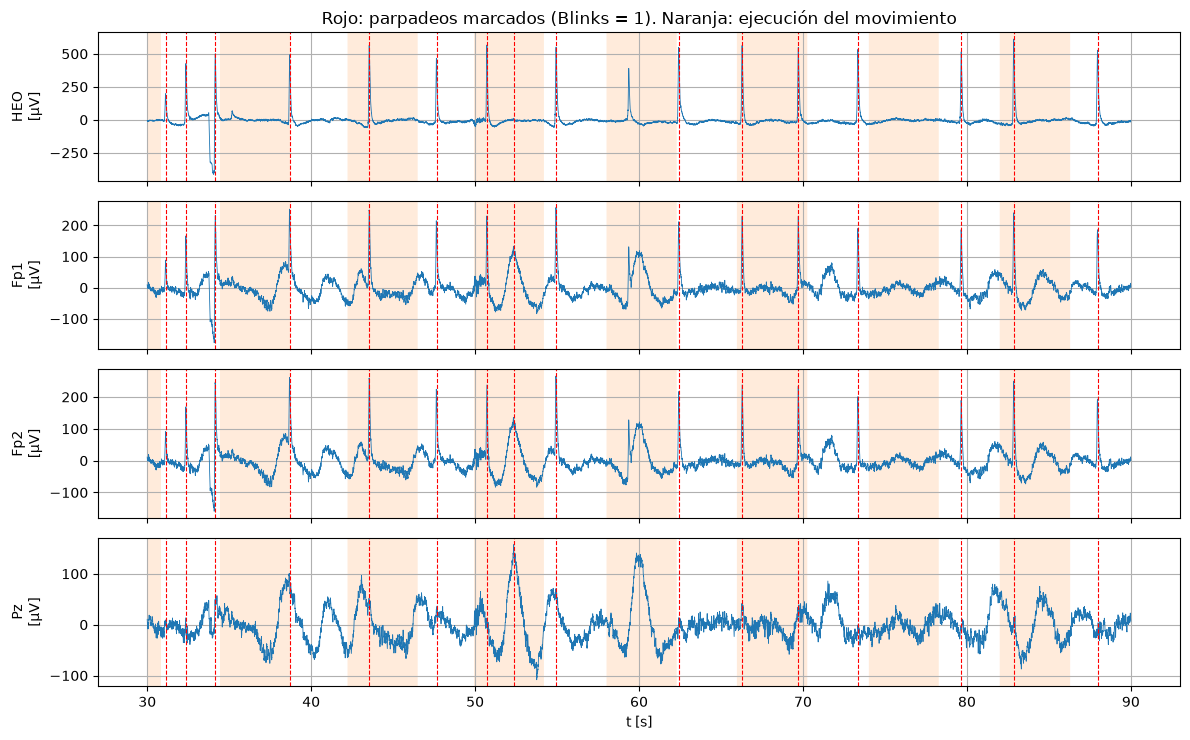

In [3]:
CANALES_VER = [CANAL_EOG, "Fp1", "Fp2", "Pz"]
T_VER = (30, 90)                                   # Tramo a mirar [s]

i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER]
fig, axs = plt.subplots(len(CANALES_VER), 1, figsize=(12, 7.5), sharex=True)
for ax, n in zip(axs, CANALES_VER):
    ax.plot(t[i0:i1], DATOS[n][i0:i1], lw=0.6)
    ax.fill_between(t[i0:i1], 0, 1, where=FASE[i0:i1] == "ejecución", transform=ax.get_xaxis_transform(),
                    color="tab:orange", alpha=0.15, lw=0)
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.8, ls="--")
    ax.set_ylabel(f"{n}\n[µV]")
    ax.grid(True)
axs[0].set_title("Rojo: parpadeos marcados (Blinks = 1). Naranja: ejecución del movimiento")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: los parpadeos en el tiempo
- **Cada línea roja cae sobre un pico:** ~250–550 µV en `HEO`, ~200 µV en `Fp1` y `Fp2`, casi nada en `Pz`.
- **Lo que importa para este notebook es el espacio entre picos:** `HEO` queda casi plano (±20 µV) durante varios segundos y después tiene un pico de ~0.2 s. Toda la información sobre cuánto parpadeo llega a `Fp1` está en esos picos.
- **No todo pico de `HEO` está marcado:** el de ~380 µV a los 59.4 s no tiene línea roja, y la deflexión de −400 µV a los 34 s es un movimiento de ojos, no un parpadeo. El filtro los ve igual, porque están en `x`; las marcas solo se usan para medir.
- Las ondas lentas de `Pz` (y de todos los canales de EEG) son la parte común que no está en `HEO` (2.3).

### 2.2 Cuánto parpadeo llega a cada canal (repaso)
Promedio sincronizado: recortar ±1 s alrededor de cada parpadeo y promediar. Lo atado al parpadeo se suma; el EEG tiende a 0. El cociente entre el pico de cada canal y el de `HEO` estima **`β`**, la fracción del parpadeo de la referencia que llega a ese electrodo (en el proyecto 1 lo llamábamos `λ`).

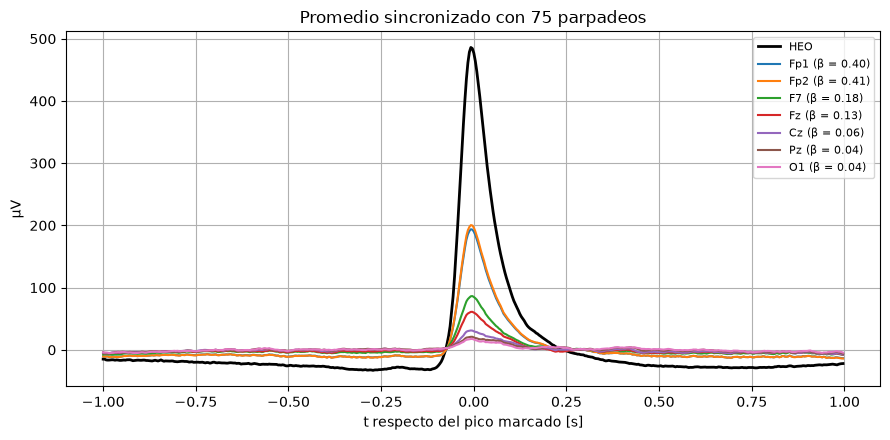

β más grandes: {'Fp2': 0.41, 'Fpz': 0.41, 'Fp1': 0.4, 'AF3': 0.32, 'AF4': 0.23}
β atrás: {'Cz': 0.06, 'Pz': 0.04, 'O1': 0.04}


In [4]:
VENTANA = int(1 * FS)                              # ±1 s alrededor de cada parpadeo
tau = np.arange(-VENTANA, VENTANA) / FS


def promedio_sincronizado(x, picos):
    """Promedio de x en ventanas de ±VENTANA alrededor de cada pico."""
    tramos = [x[k - VENTANA:k + VENTANA] for k in picos if VENTANA <= k < len(x) - VENTANA]
    return np.mean(tramos, axis=0)


prom_eog = promedio_sincronizado(DATOS[CANAL_EOG], PARPADEOS)
k_pico = np.argmax(np.abs(prom_eog))               # Muestra del pico del parpadeo promedio en HEO
BETA = pd.Series({n: promedio_sincronizado(DATOS[n], PARPADEOS)[k_pico] / prom_eog[k_pico]
                  for n in CANALES_BUENOS})        # β: amplitud en el canal / amplitud en HEO

CANALES_PROM = ["Fp1", "Fp2", "F7", "Fz", "Cz", "Pz", "O1"]   # De adelante hacia atrás
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tau, prom_eog, "k", lw=2, label=CANAL_EOG)
for n in CANALES_PROM:
    ax.plot(tau, promedio_sincronizado(DATOS[n], PARPADEOS), label=f"{n} (β = {BETA[n]:.2f})")
ax.set_title(f"Promedio sincronizado con {len(PARPADEOS)} parpadeos")
ax.set_xlabel("t respecto del pico marcado [s]")
ax.set_ylabel("µV")
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("β más grandes:", BETA.sort_values(ascending=False).head(5).round(2).to_dict())
print("β atrás:", BETA[["Cz", "Pz", "O1"]].round(2).to_dict())

### Qué mirar: el parpadeo promedio
- **Igual que en el proyecto 1:** pico de 485 µV en `HEO`, ~200 µV en `Fp1`/`Fp2` (`β` ≈ 0.4) y 15–30 µV atrás (`β` ≈ 0.04 en `Pz` y `O1`).
- **Misma forma y mismo instante en todos los canales:** solo cambia la escala. El camino ojo→electrodo es casi una ganancia.
- **Para el filtro:** en `Fp1` hay que aprender, en esencia, un número (`β ≈ 0.4`), y solo se puede aprender cuando hay parpadeo.

### 2.3 El resto de la inspección del proyecto 1, en una tabla
No se repite: está en §2.5–§2.10 de `proyecto1_eyebci.ipynb`. Lo que sale de ahí y se mantiene acá:

| Pregunta | Respuesta (proyecto 1) | Qué decide |
|---|---|---|
| ¿Retardo ojo→electrodo? | 0 ms (≤ 1 muestra): el camino es casi una ganancia. | `M = 3` alcanza (se verificó con un barrido de 1 a 8). |
| ¿`HEO` trae EEG? | ρ(`HEO`, `Fp1`) = 0.9 con parpadeos y ≈ 0.17 sin ellos; mediana de los canales ≈ 0. | `HEO` sirve de referencia: casi no hay EEG que se pueda restar por error. |
| ¿Frecuencias? | El EOG está por debajo de ~10 Hz, encima de δ y θ. | Un pasa-altos fijo se llevaría EEG: hace falta el filtro adaptativo. |
| ¿Ruido que no es de los ojos? | Una parte lenta (0.5–3 Hz) común a todos los canales de EEG, que no está en `HEO`. | Ningún filtro con esta referencia la saca: queda en `e(n)`. |
| ¿Señal sin parpadeos? | 78 % del tiempo, en tramos cortos (mediana 3.2 s). | Es lo que vuelve frágil a un algoritmo que normaliza (proyecto 1, §4). |

**Decisiones:** `y` = `Fp1` y `Fp2`, `Pz` de control, `x` = `HEO`, `M = 3`.

### 2.4 ¿Cada cuánto hay un parpadeo? (nueva: primera cota para `λ`)
**Por qué importa.** RLS minimiza `E(n) = Σ λ^(n−j) |e(j)|²`: los datos de hace `k` muestras pesan `λ^k`. La **memoria** del algoritmo es

`τ = −1 / ln λ ≈ 1 / (1 − λ)` muestras.

En este problema, **la información para aprender `w` está solo en los parpadeos**: entre parpadeos `HEO` casi no se mueve y `e(n)` es EEG, que no tiene nada que ver con `x(n)` (proyecto 1, §4). Si la memoria de RLS es más corta que el tiempo entre parpadeos, entre uno y otro el algoritmo **se olvida del último parpadeo** y se queda aprendiendo solo de EEG.

La celda calcula el tiempo entre parpadeos consecutivos y lo compara con `τ` para varios `λ`.

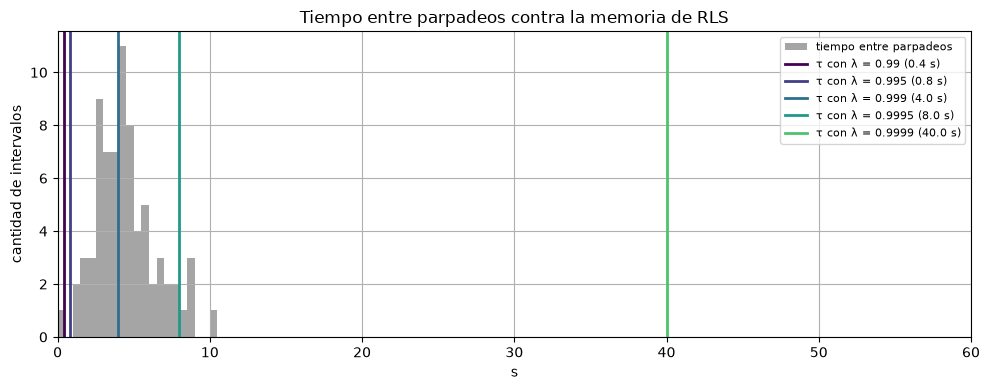

         τ [muestras]  τ [s]  parpadeos en τ  % intervalos > τ
λ                                                             
0.99000          99.0    0.4             0.1              99.0
0.99500         199.0    0.8             0.2              99.0
0.99900         999.0    4.0             0.9              57.0
0.99950        1999.0    8.0             1.8               7.0
0.99990        9999.0   40.0             9.0               0.0
0.99995       19999.0   80.0            17.9               0.0

Tiempo entre parpadeos: media 4.5 s, mediana 4.2 s, mínimo 0.2 s, máximo 10.2 s


In [5]:
intervalos = np.diff(PARPADEOS) / FS              # Tiempo entre parpadeos consecutivos [s]
LAMBDAS = [0.99, 0.995, 0.999, 0.9995, 0.9999, 0.99995]


def memoria(lam):
    """τ = -1/ln λ, en segundos."""
    return -1 / np.log(lam) / FS


fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(intervalos, bins=np.arange(0, intervalos.max() + 1, 0.5), color="tab:gray", alpha=0.7,
        label="tiempo entre parpadeos")
colores = plt.cm.viridis(np.linspace(0, 0.9, len(LAMBDAS)))
for lam, c in zip(LAMBDAS, colores):
    if memoria(lam) < 60:
        ax.axvline(memoria(lam), color=c, lw=2, label=f"τ con λ = {lam} ({memoria(lam):.1f} s)")
ax.set_xlabel("s")
ax.set_ylabel("cantidad de intervalos")
ax.set_title("Tiempo entre parpadeos contra la memoria de RLS")
ax.set_xlim(0, 60)
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

filas = {lam: {"τ [muestras]": round(-1 / np.log(lam)), "τ [s]": round(memoria(lam), 1),
               "parpadeos en τ": round(memoria(lam) / intervalos.mean(), 1),
               "% intervalos > τ": round(100 * np.mean(intervalos > memoria(lam)))} for lam in LAMBDAS}
print(pd.DataFrame(filas).T.rename_axis("λ").to_string())
print(f"\nTiempo entre parpadeos: media {intervalos.mean():.1f} s, mediana {np.median(intervalos):.1f} s, "
      f"mínimo {intervalos.min():.1f} s, máximo {intervalos.max():.1f} s")

### Qué mirar: tiempo entre parpadeos y memoria
- **Hay un parpadeo cada 4.5 s en promedio** (mediana 4.2 s). El intervalo más largo es de 10.2 s. El mínimo, 0.2 s, es un parpadeo doble.
- **Con `λ = 0.99` (el valor "de libro") la memoria es 0.4 s:** el 99 % de los intervalos son más largos. Entre un parpadeo y el siguiente, RLS se olvida del parpadeo casi por completo y aprende solo de EEG.
- **Con `λ = 0.999` (4 s), el 57 % de los intervalos son más largos que la memoria.** Todavía se olvida en la mitad de los casos.
- **Con `λ = 0.9995` (8 s) ya solo el 7 %, y con `λ ≥ 0.9999` (40 s o más) ninguno:** la memoria abarca 9 parpadeos o más.
- **Primera cota:** para que en la memoria de RLS siempre haya algún parpadeo, **`λ ≳ 0.9995`**. Para que haya varios, `λ ≈ 0.9999`.
- **Lo que esta cuenta no dice:** si `λ` cerca de 1 tiene alguna desventaja. La teoría (`9. RLS.pdf`) dice que el desajuste es `≈ M·(1−λ)/(1+λ)`, que también baja con `λ → 1`. El costo es el tracking: no podría seguir un camino ojo→electrodo que cambie más rápido que `τ`. Si el camino es una ganancia fija, como parece, eso no molesta. Lo medimos en §5.

### 2.5 ¿Qué potencia de `HEO` "ve" RLS en cada instante? (nueva)
**La cuenta.** RLS estima la correlación de la entrada con la misma ventana exponencial:

`R̂(n) = λ·R̂(n−1) + x(n)xᵀ(n)`

y la ganancia que corrige `w` es `g(n) = R̂⁻¹(n)·x(n)`. Para `M = 1` es una cuenta escalar: `R̂(n) ≈ P_λ(n) / (1 − λ)`, con

`P_λ(n) = (1 − λ)·Σ λ^(n−j) x²(j)`

la **potencia de `HEO` promediada con la ventana de RLS**. La corrección queda `Δw = x(n)·e(n)·(1 − λ) / P_λ(n)`: cuando `P_λ` baja, el paso sube, igual que `μ(n) = μ̃ / ‖x(n)‖²` en NLMS. **NLMS con δ chico es el caso extremo: estima la potencia con solo las `M = 3` últimas muestras.** RLS la estima con `τ` muestras.

La celda calcula `P_λ(n)` para tres `λ` (un filtro IIR de primer orden sobre `x²`) y la compara con `‖x(n)‖² / M`, lo que usaba NLMS.

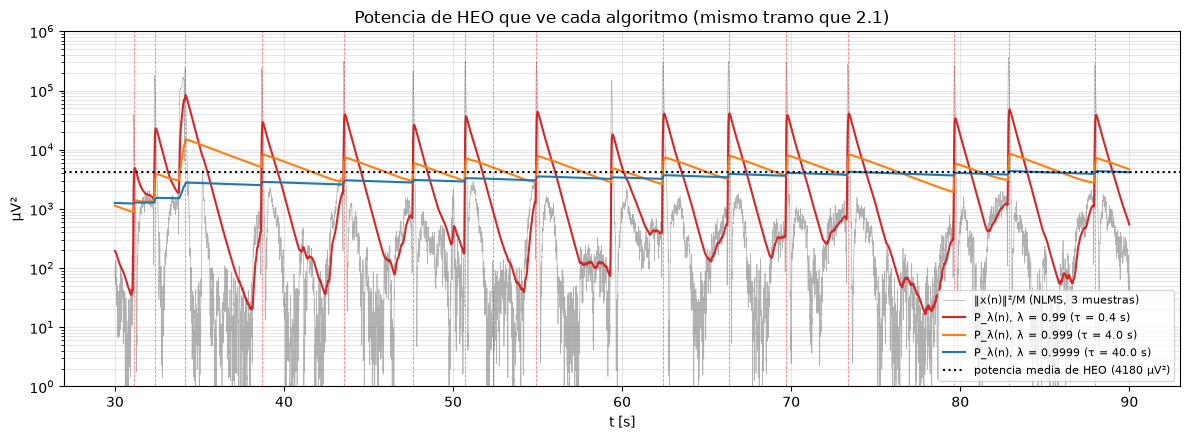

                   τ [s] P_λ mín [µV²] P_λ máx [µV²] máx / mín media / mín
0.99                 0.4          15.0       83319.0    5462.1       275.0
0.995                0.8          35.0       52346.0    1485.7       119.4
0.999                4.0         616.0       14867.0      24.1         6.9
0.9995               8.0        1446.0        8794.0       6.1         2.9
0.9999              40.0        3110.0        5451.0       1.8         1.3
0.99995             80.0        3312.0        4687.0       1.4         1.2
NLMS (3 muestras)  0.012           0.0        426024     2e+07       2e+05


In [6]:
x2 = DATOS[CANAL_EOG]**2


def potencia_lambda(lam, x2=x2):
    """P_λ(n) = (1-λ) Σ λ^(n-j) x²(j): un IIR de primer orden sobre x²."""
    return lfilter([1 - lam], [1, -lam], x2)


pot_nlms = np.convolve(x2, np.ones(3), mode="full")[:N_MUESTRAS] / 3    # ‖x(n)‖² / M con M = 3
LAMBDAS_VER = [0.99, 0.999, 0.9999]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.semilogy(t[i0:i1], pot_nlms[i0:i1], color="tab:gray", lw=0.5, alpha=0.6, label="‖x(n)‖²/M (NLMS, 3 muestras)")
for lam, c in zip(LAMBDAS_VER, ["tab:red", "tab:orange", "tab:blue"]):
    ax.semilogy(t[i0:i1], potencia_lambda(lam)[i0:i1], color=c, lw=1.5,
                label=f"P_λ(n), λ = {lam} (τ = {memoria(lam):.1f} s)")
for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
    ax.axvline(t[k], color="r", lw=0.6, ls="--", alpha=0.5)
ax.axhline(x2.mean(), color="k", ls=":", label=f"potencia media de HEO ({x2.mean():.0f} µV²)")
ax.set_ylim(1, 1e6)
ax.set_xlabel("t [s]")
ax.set_ylabel("µV²")
ax.set_title("Potencia de HEO que ve cada algoritmo (mismo tramo que 2.1)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

# Cuánto varía P_λ(n) en toda la grabación (sin el transitorio inicial de 3τ)
filas = {}
for lam in LAMBDAS:
    p = potencia_lambda(lam)[int(3 * memoria(lam) * FS):]
    filas[lam] = {"τ [s]": round(memoria(lam), 1), "P_λ mín [µV²]": round(p.min()),
                  "P_λ máx [µV²]": round(p.max()), "máx / mín": round(p.max() / p.min(), 1),
                  "media / mín": round(p.mean() / p.min(), 1)}
p = pot_nlms[FS:]
filas["NLMS (3 muestras)"] = {"τ [s]": round(3 / FS, 3), "P_λ mín [µV²]": round(p.min(), 1),
                              "P_λ máx [µV²]": round(p.max()), "máx / mín": f"{p.max() / p.min():.0e}",
                              "media / mín": f"{p.mean() / p.min():.0e}"}
print(pd.DataFrame(filas).T.to_string())

### Qué mirar: la potencia que ve RLS
- **Gris (NLMS, 3 muestras):** varía entre ~1 y ~4·10⁵ µV². Es lo que hacía que NLMS con δ chico diera pasos enormes entre parpadeos (proyecto 1, §4). En toda la grabación, máx/mín ≈ 2·10⁷.
- **Rojo (`λ = 0.99`):** el mismo problema, un poco más suave. Sube en cada parpadeo y en ~1 s ya bajó 100 veces. **Entre parpadeos, la potencia que ve RLS cae a 15–100 µV², ~275 veces menos que la media.** Ahí la ganancia `g(n)` es enorme, y en ese momento `e(n)` es solo EEG. **Predicción: con `λ = 0.99`, RLS va a fallar como NLMS con δ chico.** Lo probamos en §4.
- **Naranja (`λ = 0.999`):** diente de sierra entre ~3·10³ y ~1.5·10⁴ µV². Varía 24 veces en toda la grabación.
- **Azul (`λ = 0.9999`):** casi plana, cerca de la potencia media de `HEO` (4180 µV²). Máx/mín = 1.8: **el paso de RLS es prácticamente constante, como LMS o como NLMS con δ grande**, que fue lo que anduvo en el proyecto 1.
- **El arranque:** la azul tarda en subir (todavía está en ~1300 µV² a los 30 s, 28 s después del comienzo) porque la ventana se está llenando. Durante los primeros ~`τ` segundos, `R̂(n)` es chica y la ganancia es grande. **Ahí es donde importa la inicialización `P(−1) = δ⁻¹·I`:** δ hace de energía "inventada" mientras la ventana se llena. Con `λ` cerca de 1 ese arranque dura mucho, así que δ no es un detalle. Lo elegimos en §5.
- **La analogía con el proyecto 1:** `λ` cumple el papel que tenía δ en NLMS. Las dos cosas deciden cuánto se promedia la energía de la referencia antes de normalizar.

### Conclusiones de §2
| Pregunta | Respuesta | Qué decide |
|---|---|---|
| ¿Qué cambia respecto del proyecto 1? | Nada en los datos: mismos parpadeos, `β` ≈ 0.4 en `Fp1`/`Fp2`, 0.04 en `Pz`. | Mismas `y` (`Fp1`, `Fp2`, `Pz` de control), misma `x` (`HEO`), `M = 3`. |
| ¿Cada cuánto hay un parpadeo? | Cada 4.5 s en promedio, nunca más de 10.2 s. | La memoria de RLS tiene que ser de varios segundos. |
| ¿Qué memoria hace falta? | Con `λ = 0.99` (0.4 s), RLS ve 275 veces menos potencia entre parpadeos que en promedio. Con `λ = 0.9999` (40 s), la potencia que ve es casi constante (máx/mín = 1.8). | **Hipótesis: `λ ≈ 0.9995–0.9999`.** `λ = 0.99` debería fallar como NLMS con δ chico. |
| ¿Qué más hay que elegir? | Con `λ` cerca de 1, la ventana tarda ~`τ` en llenarse. | δ de la inicialización `P(−1) = δ⁻¹·I` importa, y se elige junto con `λ`. |

**Lo que sigue (§3–§4):** implementar RLS, chequearlo con una respuesta conocida y correrlo sobre `Fp1` con `λ = 0.99` para ver si falla como predecimos.

## §3. El filtro: RLS con HEO como referencia

> **Dónde estamos:** sabemos qué hay en las señales y tenemos una hipótesis para `λ` (§2). Ahora corremos el filtro, con los mismos pasos que §3 del proyecto 1:
> 1. Las funciones: las del proyecto 1, más `rls()`.
> 2. Sanity check: que el código haga lo que dice la teoría, con una respuesta conocida.
> 3. Primera corrida sobre los datos reales: `y` = `Fp1`, `Fp2` y `Pz` (control), `x` = `HEO`.
> 4. Pruebas sobre esa corrida: en el tiempo, los coeficientes, si el parpadeo desaparece y si se daña el EEG fuera de los parpadeos.
>
> **No hay ground truth:** de 3.3 en adelante todo son pruebas indirectas, como en el proyecto 1.

### 3.1 Funciones
Copiadas tal cual de `proyecto1_eyebci.ipynb`, §3–§4: `armar_regresor`, `matriz_regresores`, `wiener` (la solución `w_o = R⁻¹p` con promedios temporales, más `J_min`, autovalores y spread), `rrmse`, `nlms` y `lms`. NLMS y LMS se usan para comparar.

**Nueva: `rls(y, refs, M, lam, delta)`**, el RLS convencional del resumen de `9. RLS.pdf`. Para cada `n`:

| Paso | Cuenta |
|---|---|
| Ganancia alternativa | `ḡ(n) = λ⁻¹·P(n−1)·x(n)` |
| Factor de conversión | `ᾱ(n) = 1 + ḡᵀ(n)·x(n)` |
| Ganancia | `g(n) = ḡ(n) / ᾱ(n)` |
| Inversa de la correlación | `P(n) = λ⁻¹·P(n−1) − g(n)·ḡᵀ(n)` |
| Error a priori | `e(n) = y(n) − wᵀ(n−1)·x(n)` |
| Coeficientes | `w(n) = w(n−1) + g(n)·e(n)` |

con `P(−1) = δ⁻¹·I` y `w(−1) = 0`. Dos detalles:
- **Estabilidad numérica:** después de actualizar `P(n)` se fuerza la simetría con `P ← (P + Pᵀ)/2`, como recomienda el PDF.
- **Para comparar con NLMS:** la corrección es `Δw = g(n)·e(n)`. En NLMS era `Δw = μ(n)·x(n)·e(n)`. El paso de RLS en la dirección de `x` es `μ_ef(n) = xᵀg / ‖x‖²` (el mismo `μ(n)` de NLMS, en 1/µV²). Con `diag=True`, `rls()` también devuelve `μ_ef(n)` y `α(n) = 1/ᾱ(n)`.

Igual que en `nlms()`, `W[n]` son los coeficientes con los que se calculó `ŷ(n)` (en la notación del PDF, `w(n−1)`).

In [7]:
def armar_regresor(refs, n, M):
    """x(n) = [x1(n), ..., x1(n-M+1), x2(n), ..., x2(n-M+1), ...]^T (ceros antes de n = 0)."""
    x = np.zeros(len(refs) * M)
    for k, r in enumerate(refs):
        for i in range(M):
            if n - i >= 0:
                x[k * M + i] = r[n - i]
    return x


def matriz_regresores(refs, M):
    """Matriz N x (K*M) cuya fila n es x(n)^T."""
    N = len(refs[0])
    X = np.zeros((N, len(refs) * M))
    for k, r in enumerate(refs):
        for i in range(M):
            X[i:, k * M + i] = r[:N - i]
    return X


def wiener(y, refs, M):
    """Solución de Wiener estimada con promedios temporales."""
    X = matriz_regresores(refs, M)
    R = X.T @ X / len(y)                             # R = E{x x^T}
    p = X.T @ y / len(y)                             # p = E{x y}
    w_o = np.linalg.solve(R, p)                      # w_o = R^-1 p
    lam = np.linalg.eigvalsh(R)
    return {"w_o": w_o, "J_min": np.mean((y - X @ w_o)**2), "autovalores": lam,
            "spread": lam.max() / lam.min(), "P_x": np.trace(R)}


def rrmse(a, b):
    return np.sqrt(np.mean((a - b)**2) / np.mean(b**2))


def nlms(y, refs, M, mu_t, delta):
    """NLMS (proyecto 1): w(n+1) = w(n) + μ̃ x(n) e(n) / (||x(n)||² + δ)."""
    N = len(y)
    w = np.zeros(len(refs) * M)
    W, y_hat, e = np.zeros((N, len(refs) * M)), np.zeros(N), np.zeros(N)
    for n in range(N):
        x = armar_regresor(refs, n, M)
        y_hat[n] = w @ x
        e[n] = y[n] - y_hat[n]
        W[n] = w
        w = w + mu_t * x * e[n] / (x @ x + delta)
    return e, y_hat, W


def lms(y, refs, M, mu):
    """LMS (proyecto 1): w(n+1) = w(n) + μ x(n) e(n)."""
    N = len(y)
    w = np.zeros(len(refs) * M)
    W, y_hat, e = np.zeros((N, len(refs) * M)), np.zeros(N), np.zeros(N)
    for n in range(N):
        x = armar_regresor(refs, n, M)
        y_hat[n] = w @ x
        e[n] = y[n] - y_hat[n]
        W[n] = w
        w = w + mu * x * e[n]
    return e, y_hat, W


def rls(y, refs, M, lam, delta, diag=False):
    """
    RLS convencional (9. RLS.pdf), con referencias apiladas.
    Devuelve:
        e: error a priori (estimación del EEG limpio)
        y_hat: estimación del ruido en el electrodo
        W: W[n] = coeficientes con los que se calculó ŷ(n)
        (si diag) mu_ef: paso en la dirección de x, x^T g / ||x||²;  alfa: factor de conversión α(n) = 1/ᾱ(n)
    """
    N = len(y)
    X = matriz_regresores(refs, M)                   # Fila n: x(n)^T
    L = X.shape[1]
    w = np.zeros(L)                                  # w(-1) = 0
    P = np.eye(L) / delta                            # P(-1) = δ^-1 I
    W, y_hat, e = np.zeros((N, L)), np.zeros(N), np.zeros(N)
    mu_ef, alfa = np.zeros(N), np.zeros(N)
    for n in range(N):
        x = X[n]
        g_bar = P @ x / lam                          # ḡ(n) = λ^-1 P(n-1) x(n)
        a_bar = 1 + g_bar @ x                        # ᾱ(n) = 1 + ḡ^T(n) x(n)
        g = g_bar / a_bar                            # g(n) = ḡ(n) / ᾱ(n)
        P = P / lam - np.outer(g, g_bar)             # P(n) = λ^-1 P(n-1) - g(n) ḡ^T(n)
        P = (P + P.T) / 2                            # Fuerza la simetría (estabilidad numérica)
        y_hat[n] = w @ x                             # ŷ(n) = w^T(n-1) x(n)
        e[n] = y[n] - y_hat[n]                       # Error a priori
        W[n] = w
        w = w + g * e[n]                             # w(n) = w(n-1) + g(n) e(n)
        if diag:
            mu_ef[n] = (g @ x) / (x @ x) if x @ x > 0 else 0.0
            alfa[n] = 1 / a_bar
    if diag:
        return e, y_hat, W, mu_ef, alfa, P
    return e, y_hat, W

### 3.2 Sanity check
Las mismas pruebas del proyecto 1, adaptadas a RLS:
- **(a) Caso de libro:** referencia de ruido blanco e `y = s + h ∗ x`, con `h = [0.8, −0.3, 0.1]`. `w(N)` tiene que llegar a `h`, y según el PDF en unas `2M` muestras si el SNR es alto.
- **(b) La señal sintetizada del proyecto 1:** `y = Pz + h ∗ HEO`, con el `HEO` real como referencia. La respuesta sigue siendo `h`, pero el spread de `R` es 2685. **En el proyecto 1, NLMS no llegó a `h` en 336 s** (`w(N) = [0.35, −0.78, −0.10]`). La teoría dice que la convergencia de RLS no depende del spread: **esta es la primera hipótesis de RLS a probar.** Se compara con el NLMS del proyecto 1 (`μ̃ = 0.03`, `δ` chico) y con el NLMS elegido (`μ̃ = 0.3`, `δ = 100·M·P_x`).
- **(c) Con `λ = 1` y `δ` chico, RLS es LS exacto:** `w(N)` tiene que dar la solución de Wiener calculada con toda la señal (el PDF: con `λ = 1` la solución es la de LS en bloque). Reemplaza al chequeo de divergencia de NLMS, que en RLS no aplica. Además se chequea lo que la teoría dice que se cumple siempre: `0 < α(n) ≤ 1` y `P(n)` simétrica y definida positiva.

**Metaparámetros de RLS en todo §3:** `λ = 0.9999` (§2) y la inicialización "de libro" del PDF, `δ = 0.01·σx²`.

In [8]:
M = 3
LAMBDA_RLS = 0.9999                                 # Factor de olvido: memoria de 40 s (§2.4-2.5)
DELTA_REL_RLS = 0.01                                # P(-1) = δ^-1 I, con δ = 0.01 σx² (inicialización de libro)
H_PRUEBA = [0.8, -0.3, 0.1]
rng = np.random.default_rng(0)

# (a) Caso de libro: referencia blanca, y = s + h * x
N = 20000
x1 = rng.normal(size=N)
y = 0.1 * rng.normal(size=N) + lfilter(H_PRUEBA, 1, x1)
_, _, W = rls(y, [x1], M, LAMBDA_RLS, DELTA_REL_RLS * np.mean(x1**2))
n_10 = np.argmax(np.linalg.norm(W - H_PRUEBA, axis=1) < 0.1 * np.linalg.norm(H_PRUEBA))
print(f"(a) w(N) = {W[-1].round(3)}   w_o = {wiener(y, [x1], M)['w_o'].round(3)}   (h = {H_PRUEBA})")
print(f"    ‖w(n) − h‖ < 10 % de ‖h‖ desde la muestra {n_10}")

# (b) La señal sintetizada: y = Pz + h * HEO, con el HEO real como referencia
x1 = DATOS[CANAL_EOG]
P_X = np.mean(x1**2)                                # Potencia media de HEO
y = DATOS["Pz"] + lfilter(H_PRUEBA, 1, x1)
wi = wiener(y, [x1], M)
curvas_b = {}
_, _, W = rls(y, [x1], M, LAMBDA_RLS, DELTA_REL_RLS * P_X)
curvas_b[f"RLS (λ = {LAMBDA_RLS})"] = W
_, _, W = nlms(y, [x1], M, 0.03, 1e-3 * M * P_X)
curvas_b["NLMS del proyecto 1 (μ̃ = 0.03, δ chico)"] = W
_, _, W = nlms(y, [x1], M, 0.3, 100 * M * P_X)
curvas_b["NLMS elegido en el proyecto 1 (μ̃ = 0.3, δ = 100·M·P_x)"] = W
print(f"\n(b) HEO real, spread de R = {wi['spread']:.0f}, w_o = {wi['w_o'].round(3)}")
for nombre, W in curvas_b.items():
    print(f"    {nombre:58s} w(N) = {W[-1].round(3)}   ‖w(N) − w_o‖ = {np.linalg.norm(W[-1] - wi['w_o']):.3f}")

# (c) λ = 1 y δ chico: RLS = LS sobre toda la señal = Wiener con promedios temporales
e, _, W, mu_ef, alfa, P_fin = rls(y, [x1], M, 1.0, 1e-6 * P_X, diag=True)
print(f"\n(c) λ = 1: w(N) = {W[-1].round(4)}   Wiener con toda la señal = {wi['w_o'].round(4)}")
print(f"    α(n) en [{alfa.min():.3g}, {alfa.max():.3g}]   autovalores de P(N) = {np.linalg.eigvalsh(P_fin)}")

(a) w(N) = [ 0.8   -0.3    0.099]   w_o = [ 0.8   -0.3    0.099]   (h = [0.8, -0.3, 0.1])
    ‖w(n) − h‖ < 10 % de ‖h‖ desde la muestra 14

(b) HEO real, spread de R = 2685, w_o = [ 0.798 -0.281  0.119]
    RLS (λ = 0.9999)                                           w(N) = [ 0.766 -0.283  0.14 ]   ‖w(N) − w_o‖ = 0.038
    NLMS del proyecto 1 (μ̃ = 0.03, δ chico)                   w(N) = [ 0.352 -0.784 -0.097]   ‖w(N) − w_o‖ = 0.706
    NLMS elegido en el proyecto 1 (μ̃ = 0.3, δ = 100·M·P_x)    w(N) = [ 0.352  0.08  -0.058]   ‖w(N) − w_o‖ = 0.601

(c) λ = 1: w(N) = [ 0.7977 -0.2812  0.1194]   Wiener con toda la señal = [ 0.7977 -0.2812  0.1194]
    α(n) en [0.000275, 1]   autovalores de P(N) = [9.54215605e-10 2.03799993e-07 2.56199514e-06]


El chequeo (b) en el tiempo: la distancia `‖w(n) − h‖` de cada algoritmo, en escala logarítmica.

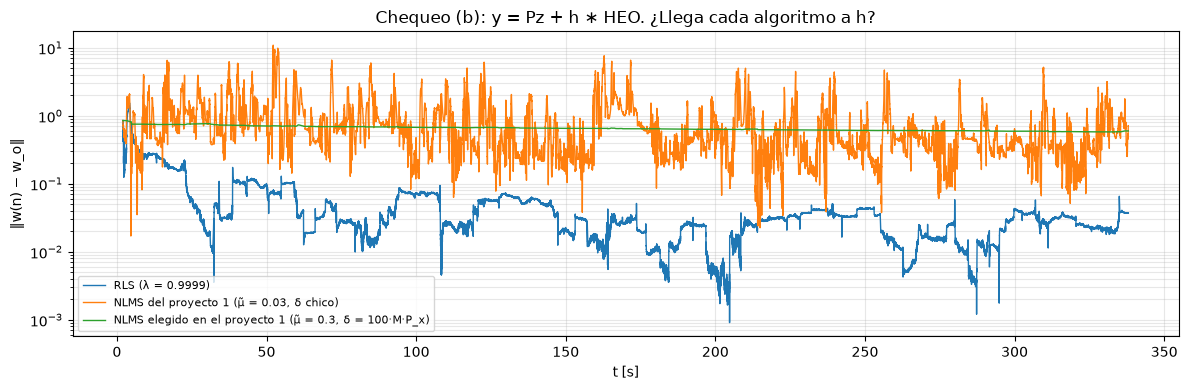

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
for nombre, W in curvas_b.items():
    ax.semilogy(t, np.linalg.norm(W - wi["w_o"], axis=1), lw=1, label=nombre)
ax.set_xlabel("t [s]")
ax.set_ylabel("‖w(n) − w_o‖")
ax.set_title("Chequeo (b): y = Pz + h ∗ HEO. ¿Llega cada algoritmo a h?")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Qué mirar: sanity check
- **(a) pasa:** `w(N) = [0.8, −0.3, 0.099]`, igual a `w_o` en tres decimales. **Llega a menos del 10 % de `h` en la muestra 14**: es el orden de `2M` que dice el PDF para SNR alto. NLMS, con la misma prueba en el proyecto 1, terminaba en `[0.776, −0.299, 0.12]` después de 20 000 muestras.
- **(b) pasa, y es la diferencia más grande con el proyecto 1:**

  | `y = Pz + h ∗ HEO` (spread 2685) | `w(N)` | `‖w(N) − w_o‖` |
  |---|---|---|
  | `w_o` | `[0.798, −0.281, 0.119]` | — |
  | **RLS `λ = 0.9999`** | `[0.766, −0.283, 0.140]` | **0.038** |
  | NLMS del proyecto 1 (`δ` chico) | `[0.352, −0.784, −0.097]` | 0.706 |
  | NLMS elegido en el proyecto 1 | `[0.352, 0.080, −0.058]` | 0.601 |

  - En el gráfico, RLS baja de 0.1 a los ~30 s y después se queda entre 0.01 y 0.1. Ninguno de los dos NLMS baja de ~0.6 en 336 s: el NLMS elegido es estable, pero sus modos lentos no llegan.
  - **Confirma la hipótesis: la convergencia de RLS no depende del spread.** RLS multiplica por `P(n) ≈ R⁻¹`, que "blanquea" la entrada: todos los modos convergen a la misma velocidad.
  - **Que no baje a 0 es lo esperado con `λ < 1`.** El PDF dice que la correlación del error de coeficientes tiende a `K(∞) ≈ (1−λ)/(1+λ)·E_o·R⁻¹`, que no es cero (memoria finita). Además se agranda con el autovalor más chico de `R` (4.6), y por eso las fluctuaciones.
- **(c) pasa:** con `λ = 1`, `w(N) = [0.7977, −0.2812, 0.1194]`, idéntico a Wiener con toda la señal en 4 decimales. El código hace LS exacto. `α(n)` queda siempre en `(0, 1]` (mínimo 0.0003, en el parpadeo más grande) y `P(N)` tiene autovalores positivos: no hay problemas numéricos.

### 3.3 Primera corrida sobre los datos reales
`procesar(canal)` corre RLS con `y` = el canal y `x` = `HEO`, y calcula Wiener sobre la misma señal para comparar. Es la función del proyecto 1, con `rls()` en lugar de `nlms()`.

**Metaparámetros:**
- `M = 3`, como en el proyecto 1.
- `λ = 0.9999`: memoria de 40 s, unos 9 parpadeos (§2.4).
- `δ = 0.01·σx²`: la inicialización del PDF. Todavía no está elegida: se barre en §5.

**Canales:** `Fp1` y `Fp2` (`β ≈ 0.4`), y `Pz` como control (`β ≈ 0.04`).

**La tabla** es la misma del proyecto 1: `w(N)` comparado con `w_o`, `J_min/P_y` (lo que no puede sacar ni el mejor filtro fijo), el spread de `R` y la correlación de `y` y de `e` con la referencia.

In [10]:
CANALES_Y = ["Fp1", "Fp2", "Pz"]                    # Los dos con más parpadeo y un control lejos de los ojos


def procesar(canal, lam=LAMBDA_RLS, delta_rel=DELTA_REL_RLS, M=M):
    """RLS con y = canal y x = HEO, más la solución de Wiener para comparar."""
    y, refs = DATOS[canal], [DATOS[CANAL_EOG]]
    e, y_hat, W = rls(y, refs, M, lam, delta_rel * np.mean(refs[0]**2))
    return {"y": y, "e": e, "y_hat": y_hat, "W": W, "wiener": wiener(y, refs, M)}


reales = {n: procesar(n) for n in CANALES_Y}

filas = {}
for n, r in reales.items():
    w_o = r["wiener"]["w_o"]
    filas[n] = {"w(N)": r["W"][-1].round(3), "w_o": w_o.round(3),
                "‖w(N)−w_o‖/‖w_o‖": np.linalg.norm(r["W"][-1] - w_o) / np.linalg.norm(w_o),
                "J_min / P_y": r["wiener"]["J_min"] / np.mean(r["y"]**2),
                "spread": r["wiener"]["spread"],
                "ρ(y, x)": np.corrcoef(r["y"], DATOS[CANAL_EOG])[0, 1],
                "ρ(e, x)": np.corrcoef(r["e"], DATOS[CANAL_EOG])[0, 1]}
print(pd.DataFrame(filas).T.to_string(float_format=lambda v: f"{v:.3g}"))

                      w(N)                     w_o ‖w(N)−w_o‖/‖w_o‖ J_min / P_y   spread ρ(y, x) ρ(e, x)
Fp1  [0.279, 0.043, 0.056]   [0.323, 0.041, 0.025]            0.165       0.433 2.68e+03   0.753 -0.0137
Fp2  [0.289, 0.044, 0.059]   [0.328, 0.048, 0.024]             0.16       0.444 2.68e+03   0.745  -0.013
Pz   [-0.034, 0.017, 0.04]  [-0.002, 0.019, 0.019]             1.39       0.992 2.68e+03  0.0896 -0.0172


### Qué mirar: RLS contra Wiener
- **Wiener es el mismo del proyecto 1:** `w_o ≈ [0.32, 0.04, 0.025]` en `Fp1` y `Fp2`, casi una ganancia de ~0.39 (`β ≈ 0.4`). `J_min/P_y` = 0.43 en `Fp1` y 0.99 en `Pz`.
- **RLS termina cerca de `w_o`:**
  - `Fp1`: `w(N) = [0.28, 0.04, 0.06]`, a 0.17 veces `‖w_o‖` (**el NLMS de la primera corrida del proyecto 1 estaba a 2.2 veces**);
  - `Fp2`: a 0.16 veces;
  - `Pz`: `w(N) = [−0.03, 0.02, 0.04]`. La distancia relativa da 1.39, pero porque `w_o ≈ 0`; en valor absoluto los coeficientes son chicos (en el proyecto 1 eran ~−0.45).
- **ρ(e, x) = −0.014 en `Fp1`** (en `y` era 0.75). Prácticamente 0, que es lo que dice el principio de ortogonalidad para `w_o`. En la primera corrida del proyecto 1 daba −0.13: restaba de más.
- `w(N)` es un solo instante. 3.5 muestra que `w(n)` no salta, así que esta vez sí se puede leer como "el valor al que llegó".

### 3.4 En el tiempo
El mismo tramo que en el proyecto 1 (de 40 a 55 s): `y`, `ŷ` y `e` en los tres canales, con los parpadeos marcados.

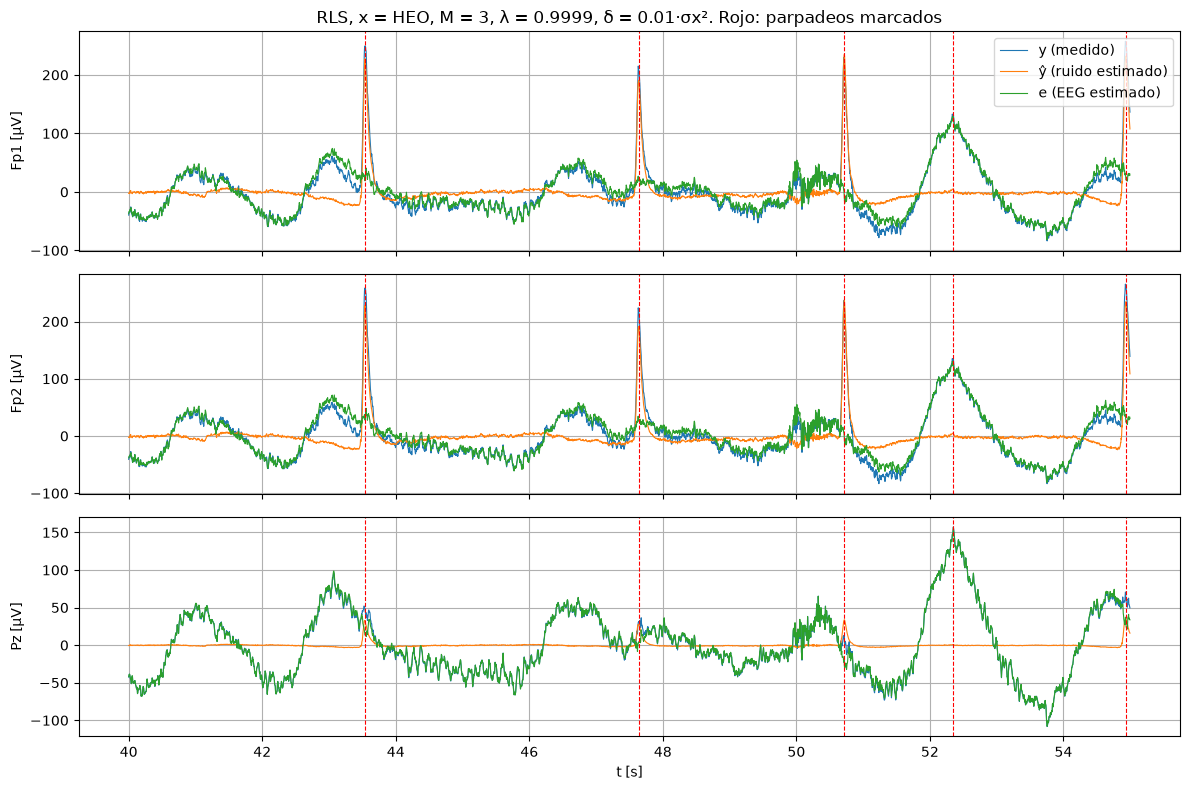

In [11]:
T_VER_3 = (40, 55)                                 # Tramo a mirar [s] (el mismo del proyecto 1)
i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER_3]

fig, axs = plt.subplots(len(CANALES_Y), 1, figsize=(12, 8), sharex=True)
for ax, (n, r) in zip(axs, reales.items()):
    ax.plot(t[i0:i1], r["y"][i0:i1], label="y (medido)", lw=0.8)
    ax.plot(t[i0:i1], r["y_hat"][i0:i1], label="ŷ (ruido estimado)", lw=0.8)
    ax.plot(t[i0:i1], r["e"][i0:i1], label="e (EEG estimado)", lw=0.8)
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.8, ls="--")
    ax.set_ylabel(f"{n} [µV]")
    ax.grid(True)
axs[0].legend(loc="upper right")
axs[0].set_title(f"RLS, x = HEO, M = {M}, λ = {LAMBDA_RLS}, δ = {DELTA_REL_RLS}·σx². Rojo: parpadeos marcados")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: y, ŷ y e en el tiempo
- **En `Fp1` y `Fp2` los parpadeos se van.** En cada línea roja, `ŷ` copia el pico de `y` (~200–250 µV) y `e` queda al nivel del resto.
- **Entre parpadeos `ŷ` queda cerca de 0:** las oscilaciones de ±100 µV que tenía NLMS en la primera corrida del proyecto 1 (52–55 s) no están. Lo que se ve son desvíos lentos de −10 a −20 µV antes de algunos parpadeos (por ejemplo, 43 s y 51–52 s). Son ~0.4 veces lo que hace `HEO` en esos momentos (los lóbulos negativos del pasa-altos y movimientos lentos de ojos), así que el filtro los resta porque están en la referencia.
- **Las ondas lentas comunes quedan en `e`** (52–53 s): no están en `HEO`, como en el proyecto 1.
- **En `Pz`, `e` va encima de `y`:** `ŷ` tiene picos de ~20–30 µV en los parpadeos, lo que corresponde a `β ≈ 0.04` × ~500 µV. Ya no aparecen los picos de ±400 µV de la primera corrida del proyecto 1.

### 3.5 Los coeficientes en el tiempo
`w(n)` de los tres coeficientes para cada canal. En línea punteada del mismo color, el `w_o` de Wiener. A la derecha, la suma `w0 + w1 + w2` (la ganancia del camino) contra la suma de `w_o`: en el proyecto 1 convergía la suma, no cada coeficiente.

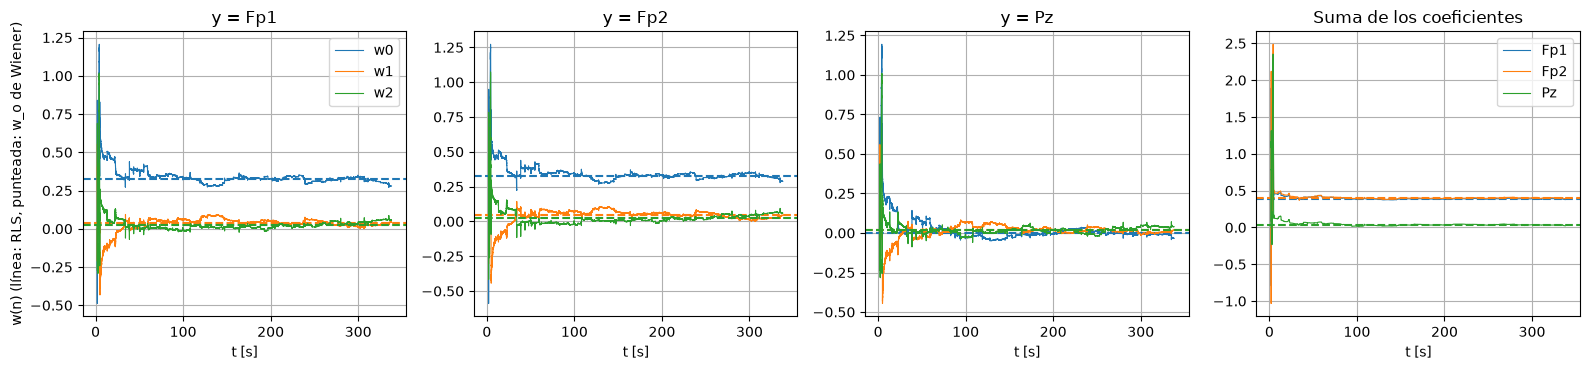

Fp1: w̄ (2.ª mitad) = [0.323 0.036 0.029]  w_o = [0.323 0.041 0.025]  std de w = 0.016  suma: 0.388 vs 0.390
Fp2: w̄ (2.ª mitad) = [0.328 0.041 0.03 ]  w_o = [0.328 0.048 0.024]  std de w = 0.017  suma: 0.399 vs 0.399
Pz: w̄ (2.ª mitad) = [0.001 0.014 0.022]  w_o = [-0.002  0.019  0.019]  std de w = 0.015  suma: 0.037 vs 0.036


In [12]:
fig, axs = plt.subplots(1, len(CANALES_Y) + 1, figsize=(16, 3.8), sharex=True)
for ax, (n, r) in zip(axs, reales.items()):
    for i in range(M):
        linea, = ax.plot(t, r["W"][:, i], label=f"w{i}", lw=0.8)
        ax.axhline(r["wiener"]["w_o"][i], color=linea.get_color(), ls="--")
    ax.set_title(f"y = {n}")
    ax.set_xlabel("t [s]")
    ax.grid(True)
for n, r in reales.items():
    linea, = axs[-1].plot(t, r["W"].sum(axis=1), lw=0.8, label=n)
    axs[-1].axhline(r["wiener"]["w_o"].sum(), color=linea.get_color(), ls="--")
axs[-1].set_title("Suma de los coeficientes")
axs[-1].set_xlabel("t [s]")
axs[-1].grid(True)
axs[-1].legend()
axs[0].set_ylabel("w(n) (línea: RLS, punteada: w_o de Wiener)")
axs[0].legend()
plt.tight_layout()
plt.show()

for n, r in reales.items():
    W2 = r["W"][len(r["W"]) // 2:]                  # Segunda mitad
    print(f"{n}: w̄ (2.ª mitad) = {W2.mean(axis=0).round(3)}  w_o = {r['wiener']['w_o'].round(3)}  "
          f"std de w = {W2.std(axis=0).mean():.3f}  suma: {W2.sum(axis=1).mean():.3f} vs {r['wiener']['w_o'].sum():.3f}")

### Qué mirar: los coeficientes
- **El arranque (primeros ~10 s):** los coeficientes saltan hasta ~1.2 y −0.5. Es la ventana llenándose (§2.5): al principio `R̂(n)` tiene pocos datos y la ganancia es grande. Después de ~50 s ya están cerca de `w_o`. **Esto depende de `δ`**, que acá es el de libro (0.01·σx²): se elige en §5.
- **Después, cada coeficiente llega a su `w_o`:**

  | Segunda mitad | `w̄` | `w_o` | suma: `w̄` / `w_o` | std de `w` |
  |---|---|---|---|---|
  | `Fp1` | `[0.323, 0.036, 0.029]` | `[0.323, 0.041, 0.025]` | 0.388 / 0.390 | 0.016 |
  | `Fp2` | `[0.328, 0.041, 0.030]` | `[0.328, 0.048, 0.024]` | 0.399 / 0.399 | 0.017 |
  | `Pz` | `[0.001, 0.014, 0.022]` | `[−0.002, 0.019, 0.019]` | 0.037 / 0.036 | 0.015 |

- **En el proyecto 1, el NLMS elegido llegaba a la suma pero no a cada coeficiente:** `w ≈ [0.20, 0.13, 0.05]` contra `w_o = [0.32, 0.04, 0.025]`, por el spread (2685). **RLS resuelve eso**, como en el chequeo (b).
- **Tiembla igual o menos que el NLMS elegido** (std 0.016 contra 0.02), así que llegar a cada coeficiente no le cuesta más ruido en `w`.

### 3.6 ¿Desaparece el parpadeo? (promedio sincronizado de y y e)
La prueba principal del proyecto 1: el promedio sincronizado de 2.2, sobre `y` y sobre `e`. Si el filtro saca el parpadeo, la curva de `e` tiene que quedar plana. La tabla da el pico a pico de cada promedio y cuánto bajó, en dB.

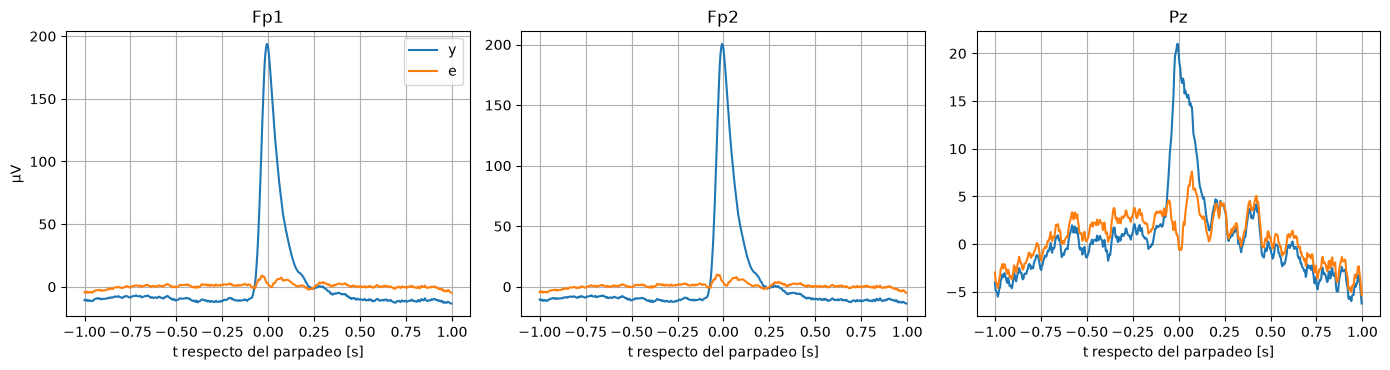

     pico a pico y [µV]  pico a pico e [µV]  reducción [dB]
Fp1               207.1                13.8           -23.5
Fp2               214.3                14.9           -23.1
Pz                 27.2                13.0            -6.4


In [13]:
fig, axs = plt.subplots(1, len(CANALES_Y), figsize=(14, 3.8))
filas = {}
for ax, (n, r) in zip(axs, reales.items()):
    py, pe = promedio_sincronizado(r["y"], PARPADEOS), promedio_sincronizado(r["e"], PARPADEOS)
    ax.plot(tau, py, label="y")
    ax.plot(tau, pe, label="e")
    ax.set_title(n)
    ax.set_xlabel("t respecto del parpadeo [s]")
    ax.grid(True)
    filas[n] = {"pico a pico y [µV]": np.ptp(py), "pico a pico e [µV]": np.ptp(pe),
                "reducción [dB]": 20 * np.log10(np.ptp(pe) / np.ptp(py))}
axs[0].set_ylabel("µV")
axs[0].legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame(filas).T.round(1).to_string())

### Qué mirar: el parpadeo promedio en y y en e
- **En `Fp1` y `Fp2` el pico baja de ~210 a ~14 µV pico a pico: −23.5 dB.** En la primera corrida del proyecto 1 bajaba −14.4 dB y quedaba un pozo de −35 µV. **Ahora no hay pozo:** queda un resto de ~+8 µV en t = 0, sin cambio de signo.
- **La línea de base de `e` queda en 0, y la de `y` estaba en ~−10 µV.** El lóbulo negativo que el pasa-altos le agrega al parpadeo también está en `HEO`, así que el filtro lo saca junto con el parpadeo.
- **En `Pz`:** el pico baja de 21 a ~7 µV y no se da vuelta (en el proyecto 1 pasaba de +21 a −14 µV). La reducción de −6.4 dB es real: queda la forma del EEG de fondo.

### 3.7 ¿Se daña el EEG fuera de los parpadeos?
Igual que en el proyecto 1: la potencia de `e` contra la de `y`, en dB (0 = no cambió; negativo = el filtro sacó; positivo = agregó), en tres lugares:
- 0.5–8 Hz **con** parpadeo, donde queremos que baje;
- 0.5–8 Hz **sin** parpadeo, donde queremos que no cambie;
- α (8–13 Hz) sin parpadeo: el EEG que menos queremos tocar.

La última columna es `RRMSE(e, y)` fuera de los parpadeos: si el filtro no hace nada ahí, da ~0. "Con parpadeo" son las muestras a menos de 0.5 s de una marca; "sin parpadeo", el resto.

In [14]:
MARGEN = int(0.5 * FS)                             # Margen alrededor de cada parpadeo [muestras]
con_parpadeo = np.zeros(N_MUESTRAS, bool)
for k in PARPADEOS:
    con_parpadeo[max(k - MARGEN, 0):k + MARGEN] = True
limpio = ~con_parpadeo                             # Muestras a más de 0.5 s de cualquier parpadeo

sos_08 = butter(4, [F_HP, 8], "bandpass", fs=FS, output="sos")
sos_alfa = butter(4, [8, 13], "bandpass", fs=FS, output="sos")


def potencia(x, sos, mascara):
    """Potencia de x filtrada con sos, solo en las muestras de la máscara."""
    return np.mean(sosfiltfilt(sos, x)[mascara]**2)


def db(a, b):
    return 10 * np.log10(a / b)


filas = {}
for n, r in reales.items():
    filas[n] = {"0.5-8 Hz con parpadeo [dB]": db(potencia(r["e"], sos_08, con_parpadeo), potencia(r["y"], sos_08, con_parpadeo)),
                "0.5-8 Hz sin parpadeo [dB]": db(potencia(r["e"], sos_08, limpio), potencia(r["y"], sos_08, limpio)),
                "α sin parpadeo [dB]": db(potencia(r["e"], sos_alfa, limpio), potencia(r["y"], sos_alfa, limpio)),
                "RRMSE(e, y) sin parpadeo": rrmse(r["e"][limpio], r["y"][limpio])}
print("Cambio de potencia de e respecto de y (0 dB = no cambió; negativo = el filtro sacó):")
print(pd.DataFrame(filas).T.round(2).to_string())

Cambio de potencia de e respecto de y (0 dB = no cambió; negativo = el filtro sacó):
     0.5-8 Hz con parpadeo [dB]  0.5-8 Hz sin parpadeo [dB]  α sin parpadeo [dB]  RRMSE(e, y) sin parpadeo
Fp1                      -14.06                       -1.32                -1.05                      0.33
Fp2                      -13.91                       -1.28                -1.10                      0.32
Pz                        -0.56                        0.02                -0.06                      0.08


### Qué mirar: daño al EEG
- **Con parpadeo, 0.5–8 Hz baja −14.1 dB en `Fp1`** (el NLMS elegido del proyecto 1: −13.0 dB; Wiener: −14.2 dB).
- **Sin parpadeo casi no toca:** α −1.05 dB y `RRMSE(e, y)` = 0.33. Son los números del NLMS elegido y de Wiener en el proyecto 1 (α −1.0 dB, RRMSE 0.31–0.32). La baja de 1 dB en α ya la tenía Wiener, así que viene de los datos (EEG frontal que ve `HEO`, o movimientos chicos de ojos), no del algoritmo.
- **En 0.5–8 Hz sin parpadeo baja −1.3 dB:** lo que el filtro resta entre parpadeos son los desvíos lentos de `HEO` de 3.4.
- **`Pz` (control) queda intacto:** cambios de −0.6 a 0 dB y `RRMSE(e, y)` = 0.08 (NLMS elegido: 0.07).

### Para discutir
**Lo que salió:**
- **RLS con `λ = 0.9999` anda en la primera corrida,** sin barrer nada: −23.5 dB en el parpadeo promedio, el control intacto, y el EEG sin parpadeos tocado igual que con Wiener.
- **Llega a cada coeficiente, no solo a la suma:** `w̄ = [0.323, 0.036, 0.029]` contra `w_o = [0.323, 0.041, 0.025]`. NLMS y LMS no podían por el spread de 2685; RLS no depende del spread (chequeo (b)).
- **Por eso saca más pico que el NLMS elegido:** queda un resto de ~10 µV contra ~22 µV (4.2).

**Preguntas abiertas:**
1. **¿`λ = 0.9999` es necesario, o cualquier `λ` sirve?** La hipótesis de §2 dice que un `λ` chico tendría que fallar como NLMS con `δ` chico → §4.
2. **El arranque:** los primeros ~10 s los coeficientes saltan hasta 1.2. ¿Lo arregla un `δ` más grande, como sugiere Moustakides para SNR bajo? → §5.
3. **¿Entre 0.999 y 0.9999, cuál?** Sin ground truth no se puede decidir bien → semi-sintético, §5.
4. **¿Le gana a LMS en condiciones parecidas?** Es lo que pide el enunciado → §5.

## §4. Diagnóstico: ¿qué hace `λ`?

> **Dónde estamos:** en §2.5 predijimos que, como RLS normaliza por la potencia de `HEO` promediada con su ventana, un `λ` chico debería fallar igual que NLMS con `δ` chico en el proyecto 1. En §3 corrimos `λ = 0.9999`. Ahora hay que confirmar que la elección importa, y por qué.
>
> Pasos (los de §4 del proyecto 1):
> 1. El paso efectivo de RLS con distintos `λ`, junto a `‖x(n)‖²` y al paso de NLMS.
> 2. Las variantes sobre los datos reales: RLS con `λ` = 0.99, 0.999 y 0.9999, contra NLMS con `δ` chico (la primera corrida del proyecto 1), el NLMS elegido y el mejor LMS del proyecto 1.
> 3. Los coeficientes de cada variante.

### 4.1 La energía de la referencia y el paso efectivo
En NLMS, `Δw = μ(n)·x(n)·e(n)` con `μ(n) = μ̃ / (‖x(n)‖² + δ)`. En RLS, `Δw = g(n)·e(n)`, y su paso en la dirección de `x` es `μ_ef(n) = xᵀg / ‖x‖²`. Se puede ver que `xᵀg = 1 − α(n)`, así que `μ_ef(n) = (1 − α(n)) / ‖x(n)‖²`: **RLS es un NLMS cuyo `μ̃` cambia en cada muestra entre 0 y 1**, según cuánto pesa `x(n)` frente a lo que ya tiene en `R̂(n)`.

La celda corre RLS sobre `Fp1` con tres `λ` y dibuja, en 60 s:
- arriba, `‖x(n)‖²`;
- en el medio, el paso efectivo: `μ_ef(n)` de cada RLS, junto con el `μ(n)` de NLMS con `δ` chico (§3 del proyecto 1) y del NLMS elegido;
- abajo, **lo que realmente se mueve `w`** en cada muestra, `‖Δw(n)‖ = ‖w(n+1) − w(n)‖`. El paso solo no alcanza: la corrección es paso × `x` × `e` (proyecto 1, §4: "la llave está en `x·e`").

El paso de RLS cambia muchísimo de una muestra a otra (depende de hacia dónde apunta `x(n)`, ver "Qué mirar"), así que las curvas del medio y de abajo están **suavizadas con una media geométrica de 0.2 s** para que se puedan leer. Las tablas usan los valores sin suavizar.

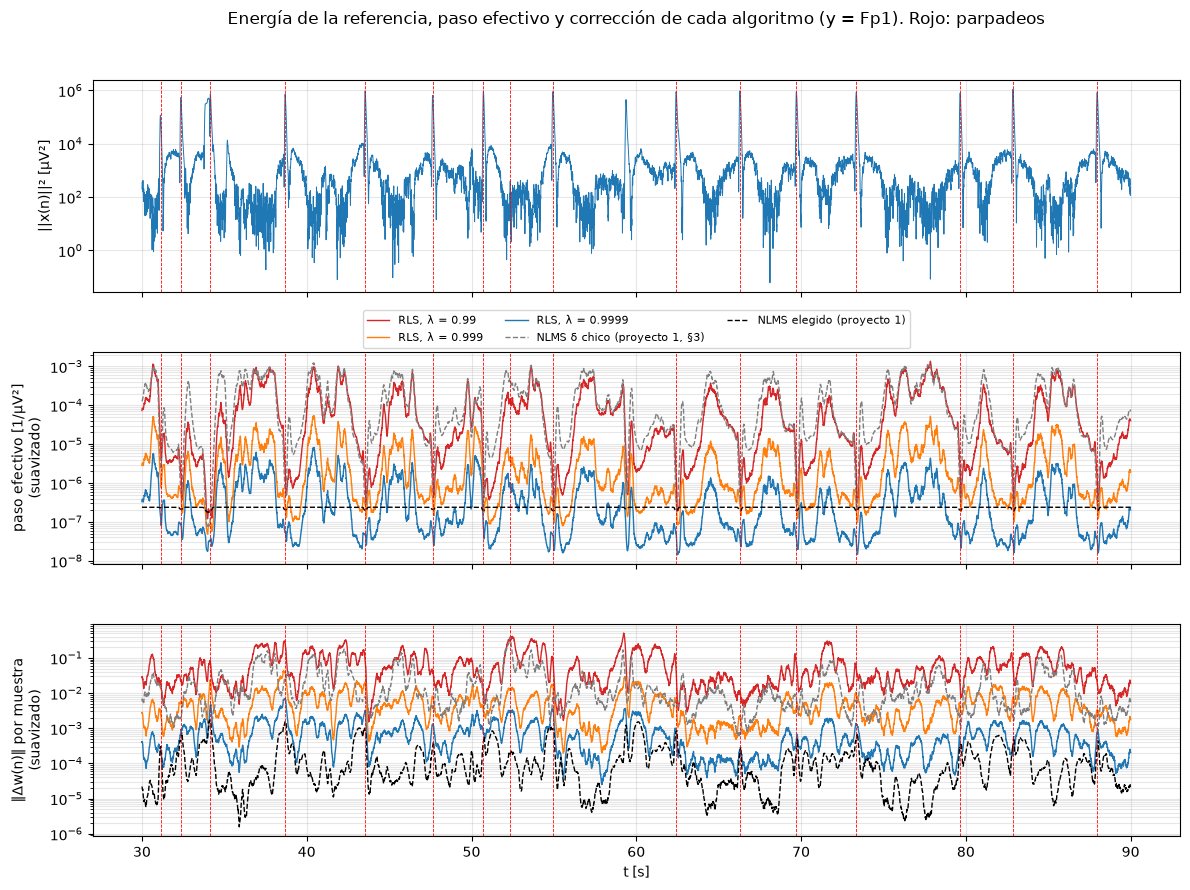

Paso efectivo mediano [1/µV²] y recorrido total de w (Σ‖Δw‖), sin los primeros 40 s:
                               paso sin parpadeo  paso en el pico  Σ‖Δw‖ sin parpadeo  Σ‖Δw‖ con parpadeo  % de Σ‖Δw‖ sin parpadeo
RLS, λ = 0.99                            5.2e-05          3.5e-07             3.5e+03             8.3e+02                       81
RLS, λ = 0.999                           1.7e-06          8.7e-08             2.9e+02                  97                       75
RLS, λ = 0.9999                          1.7e-07          9.1e-09                  33                  12                       74
NLMS δ chico (proyecto 1, §3)            8.2e-05          3.8e-08             1.2e+03             1.8e+02                       87
NLMS elegido (proyecto 1)                2.4e-07          1.5e-07                 4.9                 5.1                       49

(Sin parpadeo es el 77 % de las muestras)


In [15]:
LAMBDAS_DIAG = [0.99, 0.999, 0.9999]
norma2 = np.convolve(DATOS[CANAL_EOG]**2, np.ones(M))[:N_MUESTRAS]       # ||x(n)||²


def suavizar_log(v, largo=FS // 5):
    """Media geométrica móvil (promedio en escala log), para dibujar curvas que saltan órdenes de magnitud."""
    return 10**np.convolve(np.log10(np.maximum(v, 1e-30)), np.ones(largo) / largo, mode="same")


paso, correccion = {}, {}
for lam in LAMBDAS_DIAG:
    _, _, W, mu_ef, alfa, _ = rls(DATOS["Fp1"], [DATOS[CANAL_EOG]], M, lam, DELTA_REL_RLS * P_X, diag=True)
    paso[f"RLS, λ = {lam}"] = mu_ef
    correccion[f"RLS, λ = {lam}"] = np.r_[np.linalg.norm(np.diff(W, axis=0), axis=1), 0]
for nombre, mu_t, d in [("NLMS δ chico (proyecto 1, §3)", 0.03, 1e-3), ("NLMS elegido (proyecto 1)", 0.3, 100)]:
    paso[nombre] = mu_t / (norma2 + d * M * P_X)
    _, _, W = nlms(DATOS["Fp1"], [DATOS[CANAL_EOG]], M, mu_t, d * M * P_X)
    correccion[nombre] = np.r_[np.linalg.norm(np.diff(W, axis=0), axis=1), 0]

i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER]
colores = {"RLS, λ = 0.99": "tab:red", "RLS, λ = 0.999": "tab:orange", "RLS, λ = 0.9999": "tab:blue",
           "NLMS δ chico (proyecto 1, §3)": "tab:gray", "NLMS elegido (proyecto 1)": "k"}
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axs[0].semilogy(t[i0:i1], norma2[i0:i1], lw=0.7)
axs[0].set_ylabel("||x(n)||² [µV²]")
for nombre in paso:
    estilo = dict(lw=1, color=colores[nombre], ls="--" if "NLMS" in nombre else "-")
    axs[1].semilogy(t[i0:i1], suavizar_log(paso[nombre])[i0:i1], label=nombre, **estilo)
    axs[2].semilogy(t[i0:i1], suavizar_log(correccion[nombre])[i0:i1], **estilo)
axs[1].set_ylabel("paso efectivo [1/µV²]\n(suavizado)")
axs[2].set_ylabel("‖Δw(n)‖ por muestra\n(suavizado)")
axs[1].legend(fontsize=8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.22))
for ax in axs:
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.6, ls="--")
    ax.grid(True, which="both", alpha=0.3)
axs[0].set_title("Energía de la referencia, paso efectivo y corrección de cada algoritmo (y = Fp1). Rojo: parpadeos",
                 pad=40)
axs[2].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

# Tablas sin suavizar, después de los primeros 40 s (el arranque de λ = 0.9999)
desde = 40 * FS
sin_p = limpio.copy(); sin_p[:desde] = False
con_p = con_parpadeo.copy(); con_p[:desde] = False
picos = PARPADEOS[PARPADEOS >= desde]
tabla_paso = pd.DataFrame({nombre: {"paso sin parpadeo": np.median(paso[nombre][sin_p]),
                                    "paso en el pico": np.median(paso[nombre][picos]),
                                    "Σ‖Δw‖ sin parpadeo": correccion[nombre][sin_p].sum(),
                                    "Σ‖Δw‖ con parpadeo": correccion[nombre][con_p].sum()}
                           for nombre in paso}).T
tabla_paso["% de Σ‖Δw‖ sin parpadeo"] = 100 * tabla_paso["Σ‖Δw‖ sin parpadeo"] / (
    tabla_paso["Σ‖Δw‖ sin parpadeo"] + tabla_paso["Σ‖Δw‖ con parpadeo"])
print("Paso efectivo mediano [1/µV²] y recorrido total de w (Σ‖Δw‖), sin los primeros 40 s:")
print(tabla_paso.to_string(float_format=lambda v: f"{v:.2g}"))
print(f"\n(Sin parpadeo es el {100 * sin_p[desde:].mean():.0f} % de las muestras)")

### Qué mirar: la energía de la referencia y el paso
- **En el medio, RLS con `λ = 0.99` (rojo) va pegado a NLMS con `δ` chico (gris):** paso de ~10⁻⁴ a 10⁻³ entre parpadeos, y mínimo en los picos. En la tabla, el paso mediano sin parpadeo es 5.2·10⁻⁵ contra 8.2·10⁻⁵ de NLMS, y **150 veces más grande que en el pico.** Es la predicción de §2.5: con 0.4 s de memoria, RLS normaliza casi como NLMS.
- **Con `λ = 0.999` y `0.9999` el paso baja 30 y 300 veces,** pero sigue siendo ~20 veces más grande entre parpadeos que en el pico. **Esto ya no es la ventana:** con `λ = 0.9999`, `R̂(n)` es casi constante (§2.5). Es la dirección de `x(n)`:
  - en un parpadeo, `HEO(n)`, `HEO(n−1)` y `HEO(n−2)` son casi iguales: `x` apunta a `[1, 1, 1]`, el autovector de `R` con el autovalor más grande, y `xᵀPx/‖x‖² ≈ 1/λmax`;
  - entre parpadeos, `HEO` tiene fluctuaciones rápidas y `x` tiene componente en las direcciones de autovalores chicos (las diferencias entre coeficientes), donde `P = R⁻¹` es grande.
  
  **Es el blanqueo de RLS: da pasos grandes justo en los modos lentos.** Por eso llega a cada coeficiente, y LMS/NLMS no. Es el mismo mecanismo del chequeo (b), visto desde el paso.
- **Abajo, lo que se mueve `w`:** RLS con `λ = 0.99` recorre 3500 (suma de `‖Δw‖`), más que NLMS con `δ` chico (1200). Con `λ = 0.9999`, 33: cien veces menos. El NLMS elegido, 4.9.
- **Un detalle honesto:** aun con `λ = 0.9999`, el 74 % del recorrido de `w` pasa entre parpadeos (que son el 77 % de las muestras), contra el 49 % del NLMS elegido. RLS sigue aprendiendo entre parpadeos, pero con pasos chicos: la std de `w` es 0.016 (3.5).

### 4.2 Las variantes sobre los datos reales
Dos funciones del proyecto 1, con RLS agregado:
- **`correr()`** corre cualquiera de los algoritmos con metaparámetros comparables: para NLMS, `δ = δ_rel·M·P_x`; para LMS, `μ = μ̃ / (M·P_x)`; para RLS, `λ` y `δ = δ_rel·σx²`.
- **`pruebas_reales()`** junta las pruebas de §3 en un diccionario: `‖w̄ − w_o‖` y `std de w` en la segunda mitad de la grabación, el pico del parpadeo promedio en `y` y en `e`, la potencia en 0.5–8 Hz con parpadeo, α sin parpadeo y `RRMSE(e, y)` sin parpadeo.

**Las variantes** (todas sobre `Fp1` y `Pz`):

| Variante | Metaparámetros | De dónde sale |
|---|---|---|
| RLS `λ = 0.99` | `δ = 0.01·σx²` | El `λ` "de libro" |
| RLS `λ = 0.999` | `δ = 0.01·σx²` | Memoria de 4 s, ≈ un parpadeo |
| RLS `λ = 0.9999` | `δ = 0.01·σx²` | El de §3 |
| NLMS `δ` chico | `μ̃ = 0.03`, `δ = 10⁻³·M·P_x` | La primera corrida del proyecto 1 |
| NLMS elegido | `μ̃ = 0.3`, `δ = 100·M·P_x` | Lo elegido en el proyecto 1 |
| LMS | `μ̃ = 0.001` | El mejor LMS del semi-sintético del proyecto 1 |

In [16]:
def correr(algoritmo, y, refs, M=3, mu_t=None, delta_rel=None, lam=None):
    """Corre "RLS", "NLMS" o "LMS" con metaparámetros comparables entre ellos."""
    traza = M * sum(np.mean(r**2) for r in refs)     # tr R = M · P_x
    with np.errstate(all="ignore"):                  # LMS puede divergir: que dé nan sin avisar
        if algoritmo == "RLS":
            return rls(y, refs, M, lam, delta_rel * traza / M)
        if algoritmo == "LMS":
            return lms(y, refs, M, mu_t / traza)
        return nlms(y, refs, M, mu_t, delta_rel * traza)


def pruebas_reales(y, e, W, w_o):
    """Las pruebas de §3 (sin ground truth) en un solo diccionario."""
    py, pe = promedio_sincronizado(y, PARPADEOS), promedio_sincronizado(e, PARPADEOS)
    base = slice(0, VENTANA // 2)                    # De -1 a -0.5 s: nivel de base del promedio
    cerca = slice(VENTANA - FS // 10, VENTANA + FS // 10)   # ±0.1 s alrededor del pico marcado
    pico_y, pico_e = py[cerca] - py[base].mean(), pe[cerca] - pe[base].mean()
    mitad = len(W) // 2                              # Segunda mitad de la grabación
    with np.errstate(all="ignore"):
        return {"‖w̄ − w_o‖": np.linalg.norm(W[mitad:].mean(axis=0) - w_o),
                "std de w": W[mitad:].std(axis=0).mean(),
                "parpadeo y [µV]": pico_y[np.argmax(np.abs(pico_y))],
                "parpadeo e [µV]": pico_e[np.argmax(np.abs(pico_e))],
                "0.5-8 Hz con parp. [dB]": db(potencia(e, sos_08, con_parpadeo), potencia(y, sos_08, con_parpadeo)),
                "α sin parp. [dB]": db(potencia(e, sos_alfa, limpio), potencia(y, sos_alfa, limpio)),
                "RRMSE(e, y) sin parp.": rrmse(e[limpio], y[limpio])}


VARIANTES = {"RLS λ = 0.99": dict(algoritmo="RLS", lam=0.99, delta_rel=DELTA_REL_RLS),
             "RLS λ = 0.999": dict(algoritmo="RLS", lam=0.999, delta_rel=DELTA_REL_RLS),
             "RLS λ = 0.9999": dict(algoritmo="RLS", lam=0.9999, delta_rel=DELTA_REL_RLS),
             "NLMS δ chico": dict(algoritmo="NLMS", mu_t=0.03, delta_rel=1e-3),
             "NLMS elegido": dict(algoritmo="NLMS", mu_t=0.3, delta_rel=100),
             "LMS": dict(algoritmo="LMS", mu_t=0.001)}

diag, filas = {}, {}
for canal in ["Fp1", "Pz"]:
    w_o = reales[canal]["wiener"]["w_o"]
    for nombre, kw in VARIANTES.items():
        e, _, W = correr(y=DATOS[canal], refs=[DATOS[CANAL_EOG]], M=M, **kw)
        diag[(canal, nombre)] = (e, W)
        filas[(canal, nombre)] = pruebas_reales(DATOS[canal], e, W, w_o)

tabla_diag = pd.DataFrame(filas).T
tabla_diag.index.names = ["canal", "algoritmo"]
print(tabla_diag.round(2).to_string())

                      ‖w̄ − w_o‖  std de w  parpadeo y [µV]  parpadeo e [µV]  0.5-8 Hz con parp. [dB]  α sin parp. [dB]  RRMSE(e, y) sin parp.
canal algoritmo                                                                                                                               
Fp1   RLS λ = 0.99          0.06      0.23           202.53             8.50                   -10.82             -0.29                   0.49
      RLS λ = 0.999         0.02      0.06           202.53            11.37                   -13.82             -1.03                   0.33
      RLS λ = 0.9999        0.01      0.02           202.53             9.73                   -14.06             -1.05                   0.33
      NLMS δ chico          0.14      0.42           202.53           -36.47                    -0.32              1.84                   0.86
      NLMS elegido          0.14      0.02           202.53            21.64                   -12.97             -0.97                   0.31

### Qué mirar: las variantes sobre los datos reales
- **`λ = 0.99` falla, como se predijo en §2.5,** aunque menos que NLMS con `δ` chico:

  | `Fp1` | RLS 0.99 | RLS 0.999 | **RLS 0.9999** | NLMS `δ` chico | NLMS elegido | LMS |
  |---|---|---|---|---|---|---|
  | std de `w` | 0.23 | 0.06 | **0.02** | 0.42 | 0.02 | 0.01 |
  | `‖w̄ − w_o‖` | 0.06 | 0.02 | **0.01** | 0.14 | 0.14 | 0.18 |
  | parpadeo en `e` (en `y`: 203 µV) | +8.5 | +11.4 | **+9.7** | −36.5 | +21.6 | +24.7 |
  | 0.5–8 Hz con parpadeo [dB] | −10.8 | −13.8 | **−14.1** | −0.3 | −13.0 | −13.2 |
  | α sin parpadeo [dB] | −0.3 | −1.0 | **−1.05** | +1.8 | −1.0 | −1.0 |
  | `RRMSE(e, y)` sin parpadeo | 0.49 | 0.33 | **0.33** | 0.86 | 0.31 | 0.31 |

- **`λ = 0.99`:** el parpadeo promedio se va (+8.5 µV), pero **agrega ruido**: `w` tiembla 0.23, `RRMSE(e, y)` sin parpadeo sube a 0.49, y en `Pz` (control) **agrega +3.1 dB** en 0.5–8 Hz con `RRMSE` 0.42. Es la misma falla que NLMS con `δ` chico, más suave: estima la potencia con 99 muestras en lugar de 3.
- **`λ = 0.999` y `0.9999` dan casi lo mismo en los datos reales.** 0.9999 tiembla menos (0.02 contra 0.06) y queda más cerca de `w_o` (0.01 contra 0.02). Para decidir entre ellos hace falta saber la respuesta: §5.
- **Contra el proyecto 1:** RLS 0.9999 empata al NLMS elegido y a LMS fuera de los parpadeos (α −1.0 dB, `RRMSE` 0.31–0.33), y **saca más del pico (resto +9.7 µV contra +22 y +25)**, porque llega a cada coeficiente (`‖w̄ − w_o‖` = 0.01 contra 0.14 y 0.18).
- **En `Pz`, 0.999 y 0.9999 no lo tocan** (`RRMSE` 0.08, como el NLMS elegido 0.07 y LMS 0.04).

### 4.3 Los coeficientes de las variantes
`w(n)` en `Fp1` para las tres variantes de RLS y el NLMS elegido, todos con la misma escala (−2 a 2). La punteada es `w_o`.

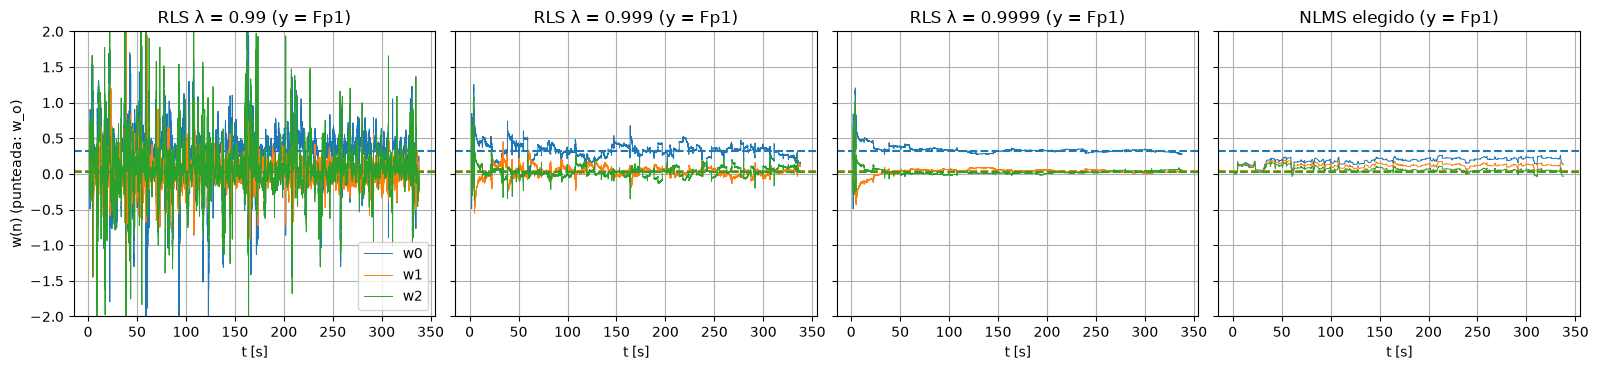

In [17]:
VER_COEF = ["RLS λ = 0.99", "RLS λ = 0.999", "RLS λ = 0.9999", "NLMS elegido"]
fig, axs = plt.subplots(1, len(VER_COEF), figsize=(16, 3.8), sharey=True)
w_o = reales["Fp1"]["wiener"]["w_o"]
for ax, nombre in zip(axs, VER_COEF):
    _, W = diag[("Fp1", nombre)]
    for i in range(M):
        linea, = ax.plot(t, W[:, i], lw=0.7, label=f"w{i}")
        ax.axhline(w_o[i], color=linea.get_color(), ls="--")
    ax.set_title(f"{nombre} (y = Fp1)")
    ax.set_xlabel("t [s]")
    ax.grid(True)
axs[0].set_ylabel("w(n) (punteada: w_o)")
axs[0].set_ylim(-2, 2)
axs[0].legend()
plt.tight_layout()
plt.show()

### Qué mirar: los coeficientes
- **`λ = 0.99`:** los coeficientes llenan la escala de −2 a 2 todo el tiempo. Es la figura de NLMS con `δ` chico del proyecto 1.
- **`λ = 0.999`:** se mueven alrededor de `w_o` (±0.2 en `w0`), con escalones en cada parpadeo.
- **`λ = 0.9999`:** después del arranque son casi rectas y **están sobre las punteadas**: cada coeficiente en su `w_o`.
- **NLMS elegido:** igual de quietos, pero **corridos**: `w0` en ~0.2 en lugar de 0.32, y `w1` en ~0.13 en lugar de 0.04. Llega a la suma, no a cada uno. Es la diferencia entre RLS y NLMS con este spread.

### Conclusiones de §4
| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Importa `λ`? | Sí. Con `λ = 0.99` RLS falla como NLMS con `δ` chico: pasos grandes entre parpadeos, `w` que salta y ruido agregado (también en el control). | 4.1: paso 150 veces más grande entre parpadeos que en el pico. 4.2: std de `w` 0.23, `RRMSE` sin parpadeo 0.49, `Pz` +3.1 dB. |
| ¿Por qué? | Con poca memoria, `R̂(n)` sigue la potencia de `HEO`, que cae 52 veces entre parpadeos (§2.5). | Es el mismo papel que tenía `δ` en NLMS. |
| ¿`λ = 0.9999` anda? | Sí, y mejor que el NLMS elegido en el pico: resto de +9.7 µV contra +21.6 µV, con el EEG fuera de los parpadeos igual de intacto. | 4.2. |
| ¿Por qué mejor? | Llega a cada coeficiente (`‖w̄ − w_o‖` = 0.01), no solo a la suma. El blanqueo `P ≈ R⁻¹` da pasos grandes en los modos lentos. | Chequeo (b), 3.5, 4.1, 4.3. |
| ¿0.999 o 0.9999? | En los datos reales casi empatan (0.9999 tiembla 3 veces menos). | Se decide en §5, con el semi-sintético. |

**Lo que sigue (§5):** el semi-sintético con realizaciones de 60 s, para elegir `λ` y el `δ` de la inicialización (el arranque de 3.5) con una respuesta conocida, y comparar con LMS y el NLMS elegido en condiciones parecidas.

## §5. Semi-sintético: elegir `λ` y `δ` con una respuesta conocida

> **Dónde estamos:** `λ = 0.9999` salió de razonar sobre los datos (§2: memoria contra tiempo entre parpadeos) y de las pruebas indirectas sobre la grabación (§3–§4). Pero sin conocer el EEG limpio, esas pruebas pueden decir que `λ = 0.99` falla, no qué `λ` es el **mejor**. Y `δ` sigue siendo el de libro.
>
> Como en el proyecto 1 (§5), armamos mezclas con pedazos de la grabación real **donde nosotros sabemos cuál es el EEG**, y medimos el algoritmo contra esa respuesta.
>
> Pasos:
> 1. Las mezclas y una realización.
> 2. La grilla `λ × δ` (Monte Carlo de 30 realizaciones por casilla).
> 3. **¿Conviene cambiar `λ` y `δ`?** Solo si la mejora es significativa (regla abajo); si no, se queda lo que ya teníamos.
> 4. RLS contra LMS y NLMS en condiciones parecidas (lo pide el enunciado).
> 5. Barrido de `M` y de SNR.

### 5.0 Las mezclas
Las mismas piezas del proyecto 1:

| Pieza | De dónde sale | Por qué |
|---|---|---|
| `s(n)`, el "EEG" | Un tramo A de un canal con `β < 0.06` (casi sin parpadeo) | EEG real: α, β y la parte común |
| `η(n)`, el parpadeo | Un tramo B de `HEO` que no se superpone con A | Parpadeos reales, sin relación con `s` |
| `h` | La forma del `w_o` de Wiener en `Fp1` | Un camino ojo→electrodo como el real |
| `β` | Ajustado para el SNR medido en `Fp1` | La misma cantidad de parpadeo que `Fp1` |
| `x(n)` | `η` + ruido blanco 20 dB abajo | Ninguna referencia es exacta |

`y(n) = s(n) + β·(h ∗ η)(n)`

**Lo que cambia: cada realización dura 60 s, no 20 s.** Con `λ = 0.9999` la memoria es de 40 s: en 20 s, todos los `λ` grandes se comportarían como `λ = 1` y la grilla no los podría distinguir. 60 s es lo más largo que entra dos veces sin superponerse en 336 s con margen para sortear.

**Las métricas** (las del proyecto 1, más dos):
- **`RRMSE` (régimen):** `RMS(e − s) / RMS(s)` en la segunda mitad de cada realización (30–60 s). Es la métrica principal, como en el proyecto 1.
- **`RRMSE` (arranque):** lo mismo en los primeros 10 s. **Es donde actúa `δ`**, y lo que importa en tiempo real (§6.6).
- `CC`, `t_conv`, sesgo y las curvas de aprendizaje `E|e(n) − s(n)|²` y `E‖w(n) − w_o‖`.
- **`SNR` de salida** = `10·log10(P_s / P(e − s))` en régimen. Acá sí se puede calcular con la definición directa, porque conocemos `s`.

**`δ` se expresa relativo a `σx²`** (`δ = δ_rel·σx²`). La regla de Moustakides del PDF, `δ = σx²·(1 − λ)^α`, cae dentro de la grilla: con `λ = 0.9999`, `α = 1` da `δ_rel = 10⁻⁴`, `α = 0` da 1, `α = −0.5` da 100 y `α = −1` da 10⁴.

In [18]:
L_TRAMO = 60 * FS                                  # Largo de cada realización: 60 s
N_REAL = 30                                        # Realizaciones del Monte Carlo
CANALES_S = [n for n in CANALES_BUENOS if abs(BETA[n]) < 0.06]   # Canales con poco parpadeo: hacen de s
w_o_fp1 = reales["Fp1"]["wiener"]["w_o"]
H = w_o_fp1 / w_o_fp1[0]                           # Forma del camino ojo -> electrodo: la de w_o en Fp1
J_MIN_FP1 = reales["Fp1"]["wiener"]["J_min"]
SNR_FP1 = 10 * np.log10(J_MIN_FP1 / (np.mean(DATOS["Fp1"]**2) - J_MIN_FP1))   # P_s / P_ruido estimado en Fp1
SNR_DB = round(SNR_FP1)                            # SNR de la mezcla: el de Fp1
SNR_REF_DB = 20                                    # Ruido de medición agregado a la referencia


def escalar_por_snr(s, eta, snr_db):
    return np.sqrt(np.mean(s**2) / (np.mean(eta**2) * 10**(snr_db / 10)))


def con_ruido(x, snr_db, rng):
    return x + rng.normal(0, np.sqrt(np.mean(x**2) / 10**(snr_db / 10)), len(x))


def suavizar(x, largo=FS // 2):
    """Promedio móvil de medio segundo (en los bordes promedia solo las muestras que hay)."""
    ventana = np.ones(largo)
    return np.convolve(x, ventana, mode="same") / np.convolve(np.ones(len(x)), ventana, mode="same")


def realizacion(rng, snr_db=SNR_DB, h=H, snr_ref_db=SNR_REF_DB):
    """
    Una mezcla y = s + β·(h ∗ η), con s y η de tramos distintos de la grabación (la del proyecto 1, con L_TRAMO = 60 s).
    Devuelve s, y, [x] y en qué muestras η tiene un parpadeo.
    """
    canal_s = rng.choice(CANALES_S)                                       # Canal que hace de EEG
    while True:                                                           # Dos tramos que no se superpongan
        i_s, i_eta = rng.integers(0, N_MUESTRAS - L_TRAMO, 2)
        if abs(i_s - i_eta) >= L_TRAMO:
            break
    s = DATOS[canal_s][i_s:i_s + L_TRAMO]                                 # EEG "limpio": tramo A
    eta = DATOS[CANAL_EOG][i_eta:i_eta + L_TRAMO]                         # Ruido de ojos: tramo B de HEO
    ruido_ojo = lfilter(h, 1, eta)                                        # Camino ojo -> electrodo
    beta = escalar_por_snr(s, ruido_ojo, snr_db)                          # β para el SNR pedido
    y = s + beta * ruido_ojo                                              # El "electrodo" armado
    x = con_ruido(eta, snr_ref_db, rng)                                   # Referencia: HEO con ruido de medición
    return s, y, [x], con_parpadeo[i_eta:i_eta + L_TRAMO]


def montecarlo(config, M=3, snr_db=SNR_DB, N_real=N_REAL, semilla=1):
    """
    Monte Carlo sobre realizacion(). config: los argumentos de correr() (algoritmo, lam, mu_t, delta_rel).
    Con la misma semilla, todas las configuraciones ven las mismas 30 mezclas: las comparaciones son pareadas.
    """
    rng = np.random.default_rng(semilla)
    J_c = np.zeros(L_TRAMO)                          # Error de cancelación E{|e(n) - s(n)|²}
    D = np.zeros(L_TRAMO)                            # Error de coeficientes E{||w(n) - w_o||}
    regimen = np.arange(L_TRAMO) >= L_TRAMO // 2     # Segunda mitad: régimen permanente
    arranque = np.arange(L_TRAMO) < 10 * FS          # Primeros 10 s
    por_real, dif_w, J_c_wiener = [], [], []
    for _ in range(N_real):
        s, y, refs, parp = realizacion(rng, snr_db)
        wi = wiener(y, refs, M)
        e, _, W = correr(y=y, refs=refs, M=M, **config)
        with np.errstate(all="ignore"):
            J_c += (e - s)**2 / N_real
            D += np.linalg.norm(W - wi["w_o"], axis=1) / N_real
            e_o = y - matriz_regresores(refs, M) @ wi["w_o"]           # Lo que deja el mejor filtro fijo
            J_c_wiener.append(np.mean((e_o - s)**2))
            dif_w.append(W[regimen].mean(axis=0) - wi["w_o"])
            con, sin = regimen & parp, regimen & ~parp
            por_real.append({"RRMSE_y": rrmse(y[regimen], s[regimen]),
                             "RRMSE": rrmse(e[regimen], s[regimen]),
                             "RRMSE_arranque": rrmse(e[arranque], s[arranque]),
                             "RRMSE_parp": rrmse(e[con], s[con]), "RRMSE_sin": rrmse(e[sin], s[sin]),
                             "RRMSE_wiener": rrmse(e_o[regimen], s[regimen]),
                             "CC": np.corrcoef(e[regimen], s[regimen])[0, 1],
                             "SNR_out": 10 * np.log10(np.mean(s[regimen]**2) / np.mean((e - s)[regimen]**2))})
    D_inf = D[regimen].mean()
    n_conv = np.argmax(D <= 1.1 * D_inf) if D_inf < D[0] else np.nan   # Primera muestra con D(n) a menos de 10 % del final
    tabla = pd.DataFrame(por_real)
    return {"J_c": J_c, "D": D, "J_c_wiener": np.mean(J_c_wiener), "t_conv": n_conv / FS,
            "sesgo": np.linalg.norm(np.mean(dif_w, axis=0)), "por_real": tabla, **tabla.mean().to_dict()}


print(f"Canales que hacen de s ({len(CANALES_S)}): {CANALES_S}")
print(f"h = {H.round(3)}   SNR de Fp1 = {SNR_FP1:.1f} dB -> SNR_DB = {SNR_DB} dB   realizaciones de {L_TRAMO / FS:.0f} s")

Canales que hacen de s (30): ['F8', 'FT8', 'C5', 'C3', 'C2', 'C4', 'C6', 'T8', 'TP7', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'TP8', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P6', 'PO5', 'PO4', 'PO6', 'PO8', 'O1', 'CB1', 'CB2']
h = [1.    0.127 0.078]   SNR de Fp1 = -1.2 dB -> SNR_DB = -1 dB   realizaciones de 60 s


### 5.1 Una realización
Lo que recibe el filtro en una de las mezclas: arriba `s(n)`, el "EEG"; en el medio `y(n)`, la mezcla, con `s` de fondo; abajo `x(n)`, la referencia, con las ventanas de parpadeo sombreadas.

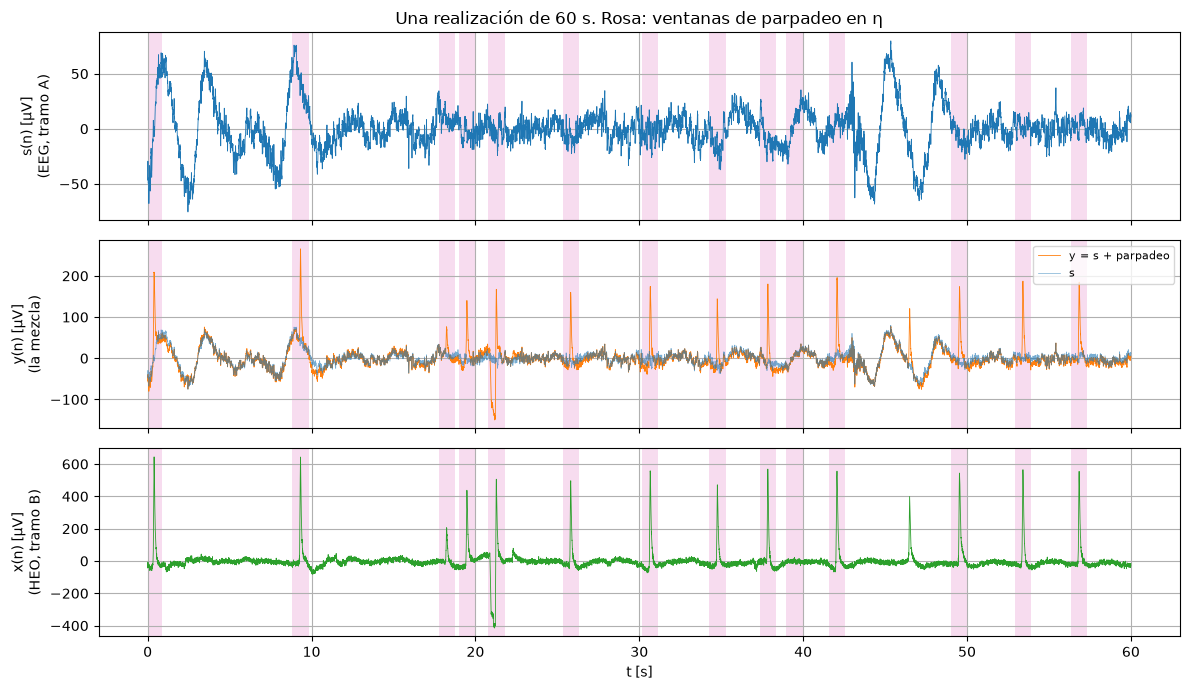

RRMSE(y, s) = 1.12 (sin filtrar); parpadeos en esta mezcla: 14


In [19]:
s, y, refs, parp = realizacion(np.random.default_rng(3))
tt = np.arange(L_TRAMO) / FS

fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axs[0].plot(tt, s, lw=0.6)
axs[0].set_ylabel("s(n) [µV]\n(EEG, tramo A)")
axs[1].plot(tt, y, lw=0.6, color="tab:orange", label="y = s + parpadeo")
axs[1].plot(tt, s, lw=0.5, color="tab:blue", alpha=0.6, label="s")
axs[1].set_ylabel("y(n) [µV]\n(la mezcla)")
axs[1].legend(loc="upper right", fontsize=8)
axs[2].plot(tt, refs[0], lw=0.6, color="tab:green")
axs[2].set_ylabel("x(n) [µV]\n(HEO, tramo B)")
for ax in axs:
    ax.fill_between(tt, 0, 1, where=parp, transform=ax.get_xaxis_transform(), color="tab:pink", alpha=0.25, lw=0)
    ax.grid(True)
axs[0].set_title("Una realización de 60 s. Rosa: ventanas de parpadeo en η")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()
print(f"RRMSE(y, s) = {rrmse(y, s):.2f} (sin filtrar); parpadeos en esta mezcla: {np.sum(np.diff(parp.astype(int)) == 1)}")

### Qué mirar: una realización
- **Arriba, `s(n)`:** EEG real de un canal de atrás, con las ondas lentas de la parte común (por ejemplo, 0–10 s y 43–48 s).
- **En el medio, `y(n)`:** los picos (~150–270 µV) caen en las franjas rosas, donde `x` tiene sus parpadeos (~400–650 µV): la proporción de `Fp1`. Entre franjas, `y ≈ s`.
- **Abajo, `x(n)`:** 14 parpadeos en 60 s, y además un movimiento de ojos de −400 µV a los 21 s que también entra en `y` (−150 µV). El filtro lo tiene que sacar igual, como en los datos reales.
- **Sin filtrar, `RRMSE(y, s)` = 1.12:** el error es más grande que el EEG mismo.

### 5.2 La grilla `λ × δ`
7 valores de `λ` (de 0.99 a 1) × 4 de `δ_rel` (`δ = δ_rel·σx²`: 0.01, el de libro; 1; 100; 10⁴), con `M = 3`. Cada casilla es un Monte Carlo de 30 realizaciones, siempre las mismas 30 mezclas.

Dos mapas: `RRMSE` en régimen (cuánto le erra a `s` una vez que aprendió) y en el arranque (los primeros 10 s). Más claro es mejor. Tarda unos minutos.

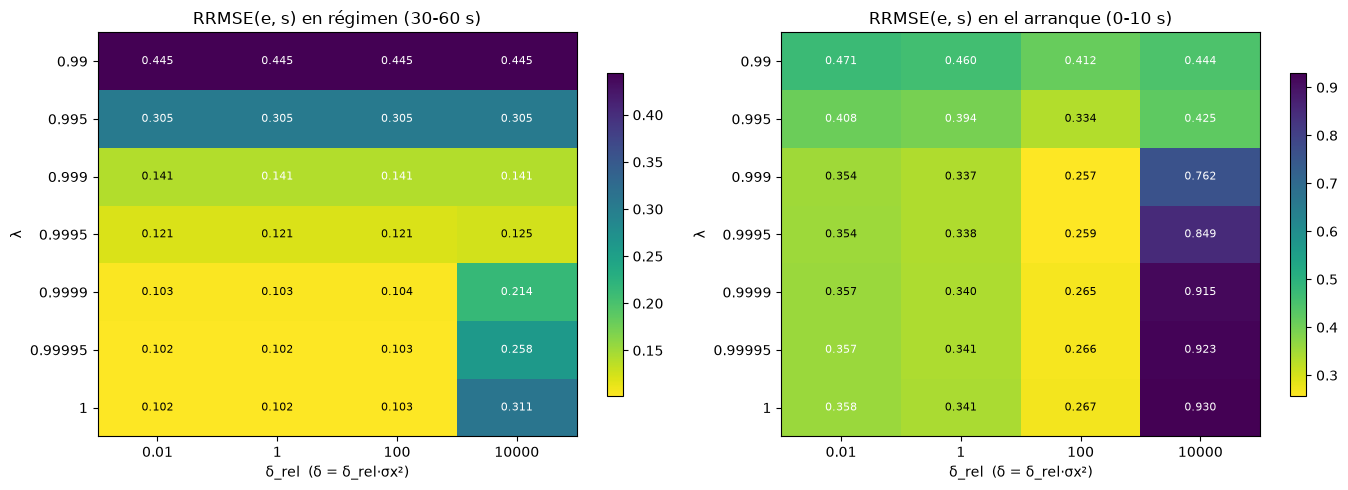

Sin filtrar: RRMSE = 1.23.  Wiener (por realización): RRMSE = 0.096

                  RRMSE  RRMSE_arranque     CC  SNR_out  t_conv  sesgo
λ       δ_rel                                                         
0.99000 0.01      0.445           0.471  0.894    7.148   1.964  0.041
        1.00      0.445           0.460  0.894    7.148   0.008  0.041
        100.00    0.445           0.412  0.894    7.148   0.016  0.041
        10000.00  0.445           0.444  0.894    7.148   0.476  0.041
0.99500 0.01      0.305           0.408  0.950   10.560   5.448  0.022
        1.00      0.305           0.394  0.950   10.560   5.448  0.022
        100.00    0.305           0.334  0.950   10.560   5.448  0.022
        10000.00  0.305           0.425  0.950   10.560   4.576  0.022
0.99900 0.01      0.141           0.354  0.989   17.267   7.724  0.000
        1.00      0.141           0.337  0.989   17.267   7.724  0.000
        100.00    0.141           0.257  0.989   17.267  12.788  0.000
        

In [20]:
LAMBDAS_GRILLA = [0.99, 0.995, 0.999, 0.9995, 0.9999, 0.99995, 1.0]
DELTAS_GRILLA = [0.01, 1, 100, 1e4]

grilla = {(lam, d): montecarlo(dict(algoritmo="RLS", lam=lam, delta_rel=d))
          for lam in LAMBDAS_GRILLA for d in DELTAS_GRILLA}


def mapa(ax, col, titulo):
    m = np.array([[grilla[(lam, d)][col] for d in DELTAS_GRILLA] for lam in LAMBDAS_GRILLA])
    im = ax.imshow(m, cmap="viridis_r", aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="w" if m[i, j] > np.nanmedian(m) else "k")
    ax.set_xticks(range(len(DELTAS_GRILLA)), [f"{d:g}" for d in DELTAS_GRILLA])
    ax.set_yticks(range(len(LAMBDAS_GRILLA)), [f"{lam:g}" for lam in LAMBDAS_GRILLA])
    ax.set_xlabel("δ_rel  (δ = δ_rel·σx²)")
    ax.set_ylabel("λ")
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, shrink=0.8)


fig, axs = plt.subplots(1, 2, figsize=(14, 5))
mapa(axs[0], "RRMSE", "RRMSE(e, s) en régimen (30-60 s)")
mapa(axs[1], "RRMSE_arranque", "RRMSE(e, s) en el arranque (0-10 s)")
plt.tight_layout()
plt.show()

tabla_grilla = pd.DataFrame({k: {c: r[c] for c in ["RRMSE", "RRMSE_arranque", "CC", "SNR_out", "t_conv", "sesgo"]}
                             for k, r in grilla.items()}).T
tabla_grilla.index.names = ["λ", "δ_rel"]
print(f"Sin filtrar: RRMSE = {grilla[(0.9999, 0.01)]['RRMSE_y']:.2f}.  Wiener (por realización): "
      f"RRMSE = {grilla[(0.9999, 0.01)]['RRMSE_wiener']:.3f}\n")
print(tabla_grilla.round(3).to_string())

### Qué mirar: la grilla
- **En régimen manda `λ`, y `δ` casi no importa** (salvo `δ_rel` = 10⁴):

  | `λ` | 0.99 | 0.995 | 0.999 | 0.9995 | **0.9999** | 0.99995 | 1 |
  |---|---|---|---|---|---|---|---|
  | `RRMSE` en régimen | 0.445 | 0.305 | 0.141 | 0.121 | **0.103** | 0.102 | 0.102 |

  Sin filtrar da 1.23, y Wiener (el mejor filtro fijo de cada mezcla) 0.096.
- **Confirma §2 y §4 con la respuesta conocida:** con `λ = 0.99` (0.4 s de memoria) el error es 4 veces el de `λ = 0.9999`. **La mejora se satura en `λ = 0.9999`:** de ahí a `λ = 1` se gana 0.001.
- **En el arranque manda `δ`:** en todas las filas con `λ ≥ 0.999`, `δ_rel = 100` es el mejor (0.257–0.267, contra 0.354–0.358 con el de libro, 0.01).
- **`δ_rel = 10⁴` es malo en los dos mapas:** 0.76–0.93 en el arranque y, con `λ ≥ 0.9999`, también empeora el régimen (0.21–0.31). `P(−1) = δ⁻¹I` funciona como si hubiera datos previos con `w = 0`, y `δ = 10⁴·σx²` "vale" tanto como toda la memoria de RLS (`σx²/(1−λ)` = 10⁴·σx² con `λ = 0.9999`). El filtro tarda decenas de segundos en despegarse de `w = 0`.
- **Contra la regla de Moustakides:** `δ_rel = 100` es `α = −0.5`. El PDF sugiere `α < −1` para SNR bajo (acá el SNR es −1 dB), que da `δ_rel ≥ 10⁴`, justo el peor. No lo investigamos más; lo que manda es la medición.
- **La columna `t_conv` no sirve para comparar acá** (ver 5.4).

### 5.3 ¿Conviene cambiar `λ` y `δ`?
**La regla, fijada antes de mirar el resultado:** se cambia un valor solo si la mejora es **significativa** y **relevante**. Como todas las casillas ven las mismas 30 mezclas, la comparación es pareada: para cada mezcla se resta el `RRMSE` de las dos configuraciones, y se mira el promedio de esas diferencias y su error estándar (SE).
- **Significativa:** mejora promedio > 2·SE (~95 %).
- **Relevante:** mejora > 5 % del `RRMSE` actual.

Si no se cumplen las dos, se queda lo que ya teníamos.

**En dos pasos:**
1. **`λ`**, con la métrica principal (`RRMSE` en régimen): la mejor casilla de toda la grilla contra la actual (`λ = 0.9999`, `δ_rel = 0.01`).
2. **`δ`**, con el `RRMSE` del arranque, que es donde actúa: dentro de la fila del `λ` elegido, el mejor `δ` contra el actual, **siempre que no empeore el régimen** de forma significativa.

In [21]:
ACTUAL = (LAMBDA_RLS, DELTA_REL_RLS)


def mejora_pareada(base, cand, col):
    """Mejora de cand respecto de base (positivo = cand es mejor), pareada por realización."""
    d = grilla[base]["por_real"][col] - grilla[cand]["por_real"][col]
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), d.mean() / grilla[base][col]


def decidir(base, cand, col):
    m, se, rel = mejora_pareada(base, cand, col)
    ok = (m > 2 * se) and (rel > 0.05)
    print(f"  {base} -> {cand}, {col}: {grilla[base][col]:.4f} -> {grilla[cand][col]:.4f}  "
          f"mejora {m:+.4f} ± {se:.4f} (SE), {100 * rel:+.1f} %  ->  {'CAMBIAR' if ok else 'no alcanza'}")
    return ok


print("Paso 1: λ (RRMSE en régimen)")
cand = min(grilla, key=lambda k: grilla[k]["RRMSE"])
paso1 = cand if cand != ACTUAL and decidir(ACTUAL, cand, "RRMSE") else ACTUAL
if cand == ACTUAL:
    print("  La mejor casilla ya es la actual.")
lam_e = paso1[0]

print(f"\nPaso 2: δ con λ = {lam_e} (RRMSE en el arranque, sin empeorar el régimen)")
base2 = paso1
cand2 = min([(lam_e, d) for d in DELTAS_GRILLA], key=lambda k: grilla[k]["RRMSE_arranque"])
if cand2 == base2:
    print("  El mejor δ para el arranque ya es el actual.")
    paso2 = base2
else:
    mejora_arr = decidir(base2, cand2, "RRMSE_arranque")
    m, se, _ = mejora_pareada(base2, cand2, "RRMSE")
    empeora_reg = m < -2 * se
    print(f"  ¿Empeora el régimen? {'sí' if empeora_reg else 'no'} (cambio {m:+.4f} ± {se:.4f})")
    paso2 = cand2 if (mejora_arr and not empeora_reg) else base2

LAMBDA_ELEGIDO, DELTA_REL_ELEGIDO = paso2
print(f"\n=> Elegido: λ = {LAMBDA_ELEGIDO}, δ = {DELTA_REL_ELEGIDO:g}·σx²   (antes: λ = {ACTUAL[0]}, δ = {ACTUAL[1]:g}·σx²)")

Paso 1: λ (RRMSE en régimen)
  (0.9999, 0.01) -> (1.0, 1), RRMSE: 0.1031 -> 0.1015  mejora +0.0016 ± 0.0013 (SE), +1.6 %  ->  no alcanza

Paso 2: δ con λ = 0.9999 (RRMSE en el arranque, sin empeorar el régimen)
  (0.9999, 0.01) -> (0.9999, 100), RRMSE_arranque: 0.3565 -> 0.2650  mejora +0.0916 ± 0.0309 (SE), +25.7 %  ->  CAMBIAR
  ¿Empeora el régimen? no (cambio -0.0004 ± 0.0002)

=> Elegido: λ = 0.9999, δ = 100·σx²   (antes: λ = 0.9999, δ = 0.01·σx²)


### Qué mirar: la decisión
- **`λ`: no se cambia.** La mejor casilla de toda la grilla es `λ = 1`, `δ_rel = 1`, con 0.1015 contra 0.1031: mejora 1.6 %, con un error estándar del mismo tamaño (0.0016 ± 0.0013). **No es significativa ni relevante.** Además, `λ = 1` no olvida nunca: no seguiría un camino que cambie, y `R̂(n)` crece sin límite en una grabación larga. **`λ = 0.9999` se queda.**
- **`δ`: se cambia a `100·σx²`.** En el arranque, el error baja de 0.357 a 0.265 (**−26 %**, 0.092 ± 0.031: 3 SE). En régimen cuesta 0.0004 (0.4 %), despreciable.
- **Elegido: `λ = 0.9999`, `δ = 100·σx²`, `M = 3`.** §6 usa estos valores.

### 5.4 RLS contra LMS y NLMS, en condiciones parecidas
El enunciado pide comparar RLS con LMS "en condiciones similares". Hay dos maneras razonables de hacerlo, y hacemos las dos:
- **(a) Cada uno con sus mejores metaparámetros**, en las mismas 30 mezclas: RLS elegido, NLMS elegido del proyecto 1 (`μ̃ = 0.3`, `δ = 100·M·P_x`) y el mejor LMS de una grilla de `μ̃` (re-barrida acá, porque las mezclas son más largas que en el proyecto 1).
- **(b) Mismo desajuste teórico, y se compara la velocidad.** Es la comparación de libro (`9. RLS.pdf`, tabla de RLS contra LMS):
  - RLS: `M_RLS ≈ M·(1 − λ)/(1 + λ)`;
  - LMS (con `w(n+1) = w(n) + μ·x·e`): `M_LMS ≈ μ·tr R / 2 = μ̃/2`.

  Igualando, `μ̃ = 2·M·(1 − λ)/(1 + λ)`. Con el mismo error en régimen (en teoría), gana el que converge más rápido.

Las curvas: el error de cancelación `E|e(n) − s(n)|²` (suavizado 0.5 s), con el piso de Wiener, y el error de coeficientes `E‖w(n) − w_o‖`.

LMS, RRMSE en régimen por μ̃: {0.0003: 0.145, 0.001: 0.159, 0.003: 0.203, 0.01: 0.272}
Mejor μ̃ de LMS: 0.0003.  μ̃ con el mismo desajuste teórico que RLS: 3.00e-04



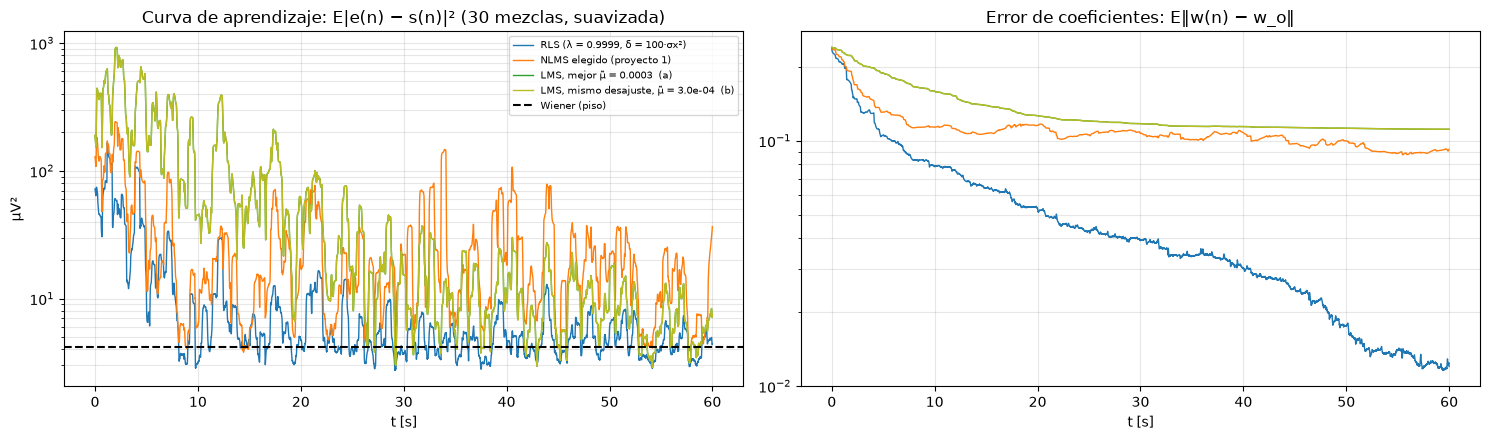

                                         RRMSE  RRMSE_arranque  RRMSE_parp  RRMSE_sin     CC  SNR_out  t_conv  sesgo
RLS (λ = 0.9999, δ = 100·σx²)            0.104           0.265       0.154      0.082  0.994   19.898  44.124  0.022
NLMS elegido (proyecto 1)                0.205           0.423       0.378      0.102  0.977   14.021  12.588  0.089
LMS, mejor μ̃ = 0.0003  (a)              0.145           0.889       0.260      0.081  0.989   17.095  21.164  0.112
LMS, mismo desajuste, μ̃ = 3.0e-04  (b)  0.145           0.889       0.260      0.081  0.989   17.095  21.164  0.112

Sin filtrar: RRMSE 1.23, SNR -1.8 dB.  Wiener por realización: RRMSE 0.096


In [22]:
MUS_LMS = [3e-4, 1e-3, 3e-3, 1e-2]
grilla_lms = {mu: montecarlo(dict(algoritmo="LMS", mu_t=mu)) for mu in MUS_LMS}
mu_lms_mejor = min(grilla_lms, key=lambda mu: grilla_lms[mu]["RRMSE"])
mu_lms_igual = 2 * M * (1 - LAMBDA_ELEGIDO) / (1 + LAMBDA_ELEGIDO)
print("LMS, RRMSE en régimen por μ̃:", {mu: round(r["RRMSE"], 3) for mu, r in grilla_lms.items()})
print(f"Mejor μ̃ de LMS: {mu_lms_mejor:g}.  μ̃ con el mismo desajuste teórico que RLS: {mu_lms_igual:.2e}\n")

NOMBRE_RLS_5 = f"RLS (λ = {LAMBDA_ELEGIDO:g}, δ = {DELTA_REL_ELEGIDO:g}·σx²)"
CMP = {NOMBRE_RLS_5: grilla[(LAMBDA_ELEGIDO, DELTA_REL_ELEGIDO)],
       "NLMS elegido (proyecto 1)": montecarlo(dict(algoritmo="NLMS", mu_t=0.3, delta_rel=100)),
       f"LMS, mejor μ̃ = {mu_lms_mejor:g}  (a)": grilla_lms[mu_lms_mejor],
       f"LMS, mismo desajuste, μ̃ = {mu_lms_igual:.1e}  (b)": montecarlo(dict(algoritmo="LMS", mu_t=mu_lms_igual))}
COLOR_CMP = dict(zip(CMP, ["tab:blue", "tab:orange", "tab:green", "tab:olive"]))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for nombre, r in CMP.items():
    axs[0].semilogy(tt, suavizar(r["J_c"]), lw=1, color=COLOR_CMP[nombre], label=nombre)
    axs[1].semilogy(tt, r["D"], lw=1, color=COLOR_CMP[nombre], label=nombre)
axs[0].axhline(CMP[NOMBRE_RLS_5]["J_c_wiener"], color="k", ls="--", label="Wiener (piso)")
axs[0].set_title("Curva de aprendizaje: E|e(n) − s(n)|² (30 mezclas, suavizada)")
axs[0].set_ylabel("µV²")
axs[1].set_title("Error de coeficientes: E‖w(n) − w_o‖")
for ax in axs:
    ax.set_xlabel("t [s]")
    ax.grid(True, which="both", alpha=0.3)
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

cols = ["RRMSE", "RRMSE_arranque", "RRMSE_parp", "RRMSE_sin", "CC", "SNR_out", "t_conv", "sesgo"]
tabla_cmp = pd.DataFrame({n: {c: r[c] for c in cols} for n, r in CMP.items()}).T
print(tabla_cmp.round(3).to_string())
base = CMP[NOMBRE_RLS_5]
print(f"\nSin filtrar: RRMSE {base['RRMSE_y']:.2f}, SNR {-20 * np.log10(base['RRMSE_y']):.1f} dB.  "
      f"Wiener por realización: RRMSE {base['RRMSE_wiener']:.3f}")

Las diferencias entre RLS y cada uno de los otros, pareadas por mezcla (positivo = RLS es mejor):

In [23]:
filas = {}
for nombre, r in CMP.items():
    if nombre == NOMBRE_RLS_5:
        continue
    for col in ["RRMSE", "RRMSE_arranque"]:
        d = r["por_real"][col] - base["por_real"][col]
        filas[(nombre, col)] = {"RLS": base[col], "el otro": r[col], "diferencia": d.mean(),
                                "SE": d.std(ddof=1) / np.sqrt(len(d)), "RLS mejor en": f"{int((d > 0).sum())}/30"}
print(pd.DataFrame(filas).T.to_string(float_format=lambda v: f"{v:.4f}"))

                                                          RLS el otro diferencia     SE RLS mejor en
NLMS elegido (proyecto 1)               RRMSE          0.1036  0.2052     0.1017 0.0075        30/30
                                        RRMSE_arranque 0.2650  0.4225     0.1576 0.0231        26/30
LMS, mejor μ̃ = 0.0003  (a)             RRMSE          0.1036  0.1450     0.0415 0.0063        29/30
                                        RRMSE_arranque 0.2650  0.8893     0.6243 0.0642        30/30
LMS, mismo desajuste, μ̃ = 3.0e-04  (b) RRMSE          0.1036  0.1450     0.0415 0.0063        29/30
                                        RRMSE_arranque 0.2650  0.8893     0.6243 0.0642        30/30


### Qué mirar: RLS contra LMS y NLMS
- **RLS es el mejor en todo, y queda a 8 % de Wiener:**

  | Semi-sintético (30 mezclas de 60 s) | `RRMSE` régimen | `RRMSE` arranque | SNR de salida |
  |---|---|---|---|
  | Sin filtrar | 1.23 | — | −1.8 dB |
  | **RLS (`λ = 0.9999`, `δ = 100·σx²`)** | **0.104** | **0.265** | **19.9 dB** |
  | NLMS elegido (proyecto 1) | 0.205 | 0.423 | 14.0 dB |
  | LMS (`μ̃ = 3·10⁻⁴`) | 0.145 | 0.889 | 17.1 dB |
  | Wiener (por mezcla, no causal) | 0.096 | — | — |

  - Contra NLMS, RLS gana en **30 de 30** mezclas en régimen y en 26 de 30 en el arranque.
  - Contra LMS, gana en 29 de 30 en régimen y en 30 de 30 en el arranque.
- **(a) y (b) dan lo mismo:** el mejor LMS de la grilla (`μ̃ = 3·10⁻⁴`) coincide con el `μ̃` que da el mismo desajuste teórico que RLS, `2·M·(1−λ)/(1+λ) = 3·10⁻⁴`. Es casualidad, pero deja la comparación de libro limpia: **con el mismo desajuste teórico, RLS llega al piso de Wiener en ~8 s y LMS en ~25 s, y LMS queda por encima** (0.145 contra 0.104). Es lo que dice el PDF: RLS converge más rápido y sin depender del spread. Un detalle: ese `μ̃` está en el borde de la grilla. Uno más chico sería todavía más lento (en el arranque ya da 0.889), así que en 60 s no ayudaría.
- **La curva de aprendizaje (izquierda):** RLS baja al piso de Wiener a los ~8 s y se queda ahí. NLMS y LMS tienen picos en cada parpadeo hasta los 20–30 s y siguen por encima del piso.
- **El error de coeficientes (derecha) explica la diferencia:**
  - RLS sigue bajando hasta el final (0.012 a los 60 s).
  - NLMS se planta en ~0.09–0.1 y LMS en 0.11: aprenden la suma de los coeficientes, no cada uno (el sesgo de la tabla: 0.022 contra 0.089 y 0.112). Es lo mismo que vimos en los datos reales.
  - **Por eso `t_conv` engaña:** mide cuándo `D(n)` llega a 10 % de su valor final. RLS da 44 s porque sigue mejorando hasta el final; NLMS da 12.6 s porque se frena antes, en un valor peor.
- **La diferencia está en los parpadeos:** `RRMSE` con parpadeo 0.154 (RLS), 0.378 (NLMS) y 0.260 (LMS); sin parpadeo, 0.082, 0.102 y 0.081. Es lo mismo que se ve en los datos reales (§6).

### 5.5 ¿Qué `M`?
RLS elegido con `M = 1, 2, 3, 5` y `8`. En el proyecto 1, NLMS empeoraba con `M = 8` porque cada coeficiente de más era un modo lento más. RLS no tiene modos lentos (no depende del spread), así que la pregunta es si cambia algo.

In [24]:
MS = [1, 2, 3, 5, 8]
res_M = {m: montecarlo(dict(algoritmo="RLS", lam=LAMBDA_ELEGIDO, delta_rel=DELTA_REL_ELEGIDO), M=m) for m in MS}
print(pd.DataFrame({m: {c: r[c] for c in ["RRMSE", "RRMSE_arranque", "RRMSE_wiener", "CC", "t_conv"]}
                    for m, r in res_M.items()}).T.rename_axis("M").round(3).to_string())

   RRMSE  RRMSE_arranque  RRMSE_wiener     CC  t_conv
M                                                    
1  0.135           0.314         0.129  0.991  34.580
2  0.105           0.268         0.099  0.994  43.256
3  0.104           0.265         0.096  0.994  44.124
5  0.104           0.281         0.096  0.994  42.236
8  0.102           0.300         0.094  0.995  41.268


### Qué mirar: el barrido de `M`
- **`M = 1` es peor** (0.135): el camino no es una ganancia pura, y Wiener con `M = 1` también empeora (0.129).
- **De `M = 2` a `M = 8` da lo mismo** (0.102–0.105), siempre a ~0.008 de Wiener.
- **`M = 8` no empeora el régimen.** Con NLMS, en el proyecto 1, pasaba de 0.22 a 0.31, porque cada coeficiente de más era un modo lento más. RLS no tiene modos lentos.
- **El arranque sí empeora un poco con `M`** (0.265 con `M = 3`, 0.300 con `M = 8`): más coeficientes para aprender con pocos datos.
- **Se queda `M = 3`:** el mejor arranque, empata en régimen, y es el mismo `M` del proyecto 1, así que la comparación es directa.

### 5.6 ¿Y con más o menos parpadeo? (barrido de SNR)
RLS elegido, NLMS elegido y el mejor LMS con el SNR de la mezcla de −10 a +10 dB (−10 dB: un electrodo con mucho parpadeo; +10 dB, con poco). La línea negra es sin filtrar.

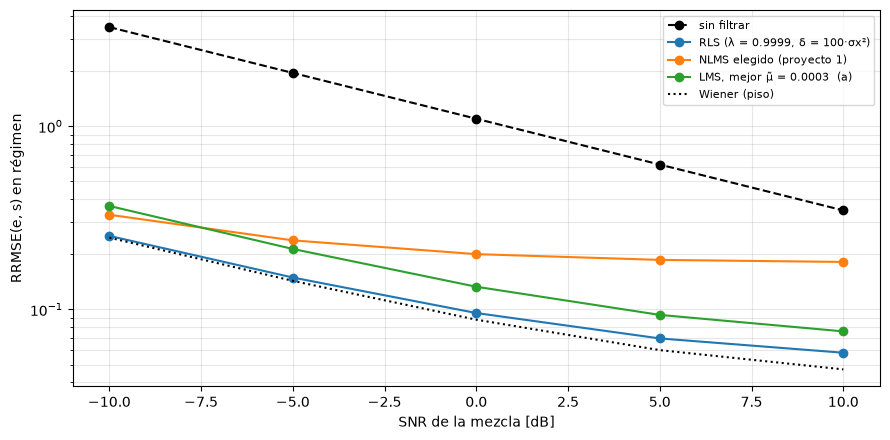

          RLS (λ = 0.9999, δ = 100·σx²)  NLMS elegido (proyecto 1)  LMS, mejor μ̃ = 0.0003  (a)  sin filtrar  Wiener
SNR [dB]                                                                                                            
-10                               0.252                      0.328                        0.367        3.470   0.246
-5                                0.149                      0.238                        0.214        1.951   0.143
 0                                0.096                      0.200                        0.133        1.097   0.088
 5                                0.069                      0.186                        0.093        0.617   0.060
 10                               0.058                      0.182                        0.076        0.347   0.047


In [25]:
SNRS = [-10, -5, 0, 5, 10]
CONF_SNR = {NOMBRE_RLS_5: dict(algoritmo="RLS", lam=LAMBDA_ELEGIDO, delta_rel=DELTA_REL_ELEGIDO),
            "NLMS elegido (proyecto 1)": dict(algoritmo="NLMS", mu_t=0.3, delta_rel=100),
            f"LMS, mejor μ̃ = {mu_lms_mejor:g}  (a)": dict(algoritmo="LMS", mu_t=mu_lms_mejor)}
res_snr = {(n, snr): montecarlo(c, snr_db=snr) for n, c in CONF_SNR.items() for snr in SNRS}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(SNRS, [res_snr[(NOMBRE_RLS_5, snr)]["RRMSE_y"] for snr in SNRS], "k--o", label="sin filtrar")
for n in CONF_SNR:
    ax.plot(SNRS, [res_snr[(n, snr)]["RRMSE"] for snr in SNRS], "-o", color=COLOR_CMP[n], label=n)
ax.plot(SNRS, [res_snr[(NOMBRE_RLS_5, snr)]["RRMSE_wiener"] for snr in SNRS], "k:", label="Wiener (piso)")
ax.set_yscale("log")
ax.set_xlabel("SNR de la mezcla [dB]")
ax.set_ylabel("RRMSE(e, s) en régimen")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(pd.DataFrame({n: {snr: res_snr[(n, snr)]["RRMSE"] for snr in SNRS} for n in CONF_SNR}
                   | {"sin filtrar": {snr: res_snr[(NOMBRE_RLS_5, snr)]["RRMSE_y"] for snr in SNRS},
                      "Wiener": {snr: res_snr[(NOMBRE_RLS_5, snr)]["RRMSE_wiener"] for snr in SNRS}}
                   ).rename_axis("SNR [dB]").round(3).to_string())

### Qué mirar: el barrido de SNR
- **RLS es el mejor con cualquier SNR, y va pegado a Wiener:** 0.252 contra 0.246 con −10 dB, y 0.058 contra 0.047 con +10 dB.
- **NLMS se frena en ~0.18 cuando hay poco parpadeo** (SNR ≥ 0 dB): es su sesgo en los coeficientes. Con poco parpadeo, lo que queda mal restado pesa más frente al EEG.
- **LMS queda entre los dos** en todo el rango.
- Con el SNR de `Fp1` (−1 dB), RLS deja la mitad de error que NLMS (0.104 contra 0.205).

### Conclusiones de §5
| Parámetro | Valor | Cómo se eligió |
|---|---|---|
| `λ` | **0.9999** (sin cambios) | §2: la memoria (40 s) abarca ~9 parpadeos. §5.2: el error en régimen baja hasta 0.9999 y ahí se satura. `λ = 1` mejora 1.6 %, no significativo (§5.3). |
| `δ` | **`100·σx²`** (antes `0.01·σx²`) | §5.2: el mejor para el arranque en todas las filas con `λ ≥ 0.999`. §5.3: −26 % de error en los primeros 10 s (3 SE), sin costo en régimen. |
| `M` | **3** (sin cambios) | §5.5: de 2 a 8 da lo mismo; 3 tiene el mejor arranque. |

**RLS contra LMS y NLMS, con la respuesta conocida:**
- **RLS: `RRMSE` 0.104** (Wiener, 0.096; sin filtrar, 1.23). NLMS elegido: 0.205. Mejor LMS: 0.145. SNR de salida: 19.9, 14.0 y 17.1 dB.
- **Con el mismo desajuste teórico, RLS converge en ~8 s y LMS en ~25 s, y LMS queda por encima.** Es el resultado de libro, y se cumple acá.
- **La razón es la misma que en los datos reales:** RLS llega a cada coeficiente (sesgo 0.022), NLMS y LMS solo a su suma (0.09–0.11). Por eso la ventaja de RLS está en los parpadeos.

## §6. Datos reales: RLS contra el NLMS del proyecto 1, como en una implementación real

> **Dónde estamos:** en §5 elegimos RLS con `λ = 0.9999` y `δ = 100·σx²`, con una respuesta conocida. Ahora lo usamos sobre la grabación cruda como se usaría en la práctica, y lo comparamos con el filtro que elegimos en el proyecto 1.
>
> **"Como en una implementación real"** quiere decir:
> - **Causal y en línea:** cada `e(n)` se calcula con `y` y `x` hasta la muestra `n`. Nada del futuro.
> - **Sin entrenamiento previo:** los dos filtros arrancan en `w = 0` al principio de la grabación. El arranque cuenta en los resultados.
> - **Metaparámetros fijos** durante los 336 s.
>
> Los filtros, sobre `Fp1`, `Fp2` y `Pz`:
>
> | Filtro | Metaparámetros | Papel |
> |---|---|---|
> | **RLS** | `λ = 0.9999`, `δ = 100·σx²`, `M = 3` | El elegido en §5 (las variables `LAMBDA_ELEGIDO`, `DELTA_REL_ELEGIDO`) |
> | **NLMS** | `μ̃ = 0.3`, `δ = 100·M·P_x`, `M = 3` | El elegido en el proyecto 1, §5–§6 |
> | **Wiener (fijo)** | `w_o = R̂⁻¹p̂` con toda la grabación | Referencia: el mejor filtro fijo. **No es causal**: usa el futuro |
>
> Pasos:
> 1. Correr los filtros y la tabla de pruebas del proyecto 1.
> 2. Superponer las salidas de NLMS y RLS: en el tiempo, en el parpadeo promedio y en frecuencia.
> 3. Comparar el SNR de cada filtro.
> 4. Ver cómo se comporta cada uno parpadeo a parpadeo desde el arranque, que es lo que importa en tiempo real.

### 6.1 Los filtros y la tabla de pruebas
`wiener_fijo()` es la del proyecto 1. Corre los tres filtros sobre los tres canales y arma la tabla de `pruebas_reales()` (4.2), más `ρ(e, x)`, que según el principio de ortogonalidad tiene que dar ~0.

**Un detalle de causalidad:** los dos adaptativos escalan su `δ` con la potencia de `HEO` (`σx²` en RLS, `P_x` en NLMS). La calculamos con toda la grabación, como en el proyecto 1, y eso no es estrictamente causal. La celda compara ese valor con el de los primeros 30 s, que sería una calibración posible en la práctica.

In [26]:
def wiener_fijo(y, refs, M):
    """El mejor filtro fijo: e = y - w_o^T x(n), con w_o de toda la grabación (no causal)."""
    w_o = wiener(y, refs, M)["w_o"]
    y_hat = matriz_regresores(refs, M) @ w_o
    return y - y_hat, y_hat, np.tile(w_o, (len(y), 1))


NOMBRE_RLS = f"RLS (λ = {LAMBDA_ELEGIDO:g})"
FILTROS = {"NLMS (proyecto 1)": dict(algoritmo="NLMS", mu_t=0.3, delta_rel=100),
           NOMBRE_RLS: dict(algoritmo="RLS", lam=LAMBDA_ELEGIDO, delta_rel=DELTA_REL_ELEGIDO)}

finales, filas = {}, {}
for canal in CANALES_Y:
    y, refs = DATOS[canal], [DATOS[CANAL_EOG]]
    w_o = reales[canal]["wiener"]["w_o"]
    for nombre, kw in FILTROS.items():
        finales[(canal, nombre)] = correr(y=y, refs=refs, M=M, **kw)
    finales[(canal, "Wiener (fijo)")] = wiener_fijo(y, refs, M)
    for nombre in list(FILTROS) + ["Wiener (fijo)"]:
        e, _, W = finales[(canal, nombre)]
        filas[(canal, nombre)] = pruebas_reales(y, e, W, w_o) | {"ρ(e, x)": np.corrcoef(e, refs[0])[0, 1]}

tabla_final = pd.DataFrame(filas).T
tabla_final.index.names = ["canal", "filtro"]
print(tabla_final.round(2).to_string())

p_cal = np.mean(DATOS[CANAL_EOG][:30 * FS]**2)
print(f"\nPotencia de HEO: toda la grabación {P_X:.0f} µV², primeros 30 s {p_cal:.0f} µV² (cociente {P_X / p_cal:.2f})")

                         ‖w̄ − w_o‖  std de w  parpadeo y [µV]  parpadeo e [µV]  0.5-8 Hz con parp. [dB]  α sin parp. [dB]  RRMSE(e, y) sin parp.  ρ(e, x)
canal filtro                                                                                                                                              
Fp1   NLMS (proyecto 1)        0.14      0.02           202.53            21.64                   -12.97             -0.97                   0.31     0.01
      RLS (λ = 0.9999)         0.00      0.02           202.53            12.27                   -14.10             -1.04                   0.32    -0.01
      Wiener (fijo)            0.00      0.00           202.53            12.14                   -14.16             -1.03                   0.32     0.00
Fp2   NLMS (proyecto 1)        0.14      0.02           209.44            23.49                   -12.85             -1.02                   0.30     0.01
      RLS (λ = 0.9999)         0.01      0.02           209.44        

### Qué mirar: la tabla de pruebas
- **Los tres sacan el parpadeo, y RLS deja la mitad de resto que NLMS, lo mismo que Wiener:**

  | `Fp1` | NLMS (proyecto 1) | **RLS** | Wiener (no causal) |
  |---|---|---|---|
  | parpadeo en `e` (en `y`: 203 µV) | +21.6 µV | **+12.3 µV** | +12.1 µV |
  | 0.5–8 Hz con parpadeo | −13.0 dB | **−14.1 dB** | −14.2 dB |
  | α sin parpadeo | −0.97 dB | −1.04 dB | −1.03 dB |
  | `RRMSE(e, y)` sin parpadeo | 0.31 | 0.32 | 0.32 |
  | `ρ(e, x)` | 0.01 | −0.01 | 0.00 |
  | `‖w̄ − w_o‖` | 0.14 | **0.00** | 0 |

  En `Fp2` es lo mismo: resto de +23.5, **+13.4** y +13.8 µV.
- **RLS, que es causal, queda igual que Wiener,** que ve toda la grabación. Llega a cada coeficiente (`‖w̄ − w_o‖` = 0.00); NLMS no (0.14).
- **Comparado con el `δ` de libro (§3):** con `δ = 0.01·σx²`, el resto de `Fp1` era +9.7 µV, un poco menos que Wiener. Con `δ = 100·σx²` (§5) es +12.3 µV, igual a Wiener. Son 2.6 µV sobre 203 µV, cerca de lo que estas pruebas indirectas pueden distinguir. El semi-sintético, que sí conoce la respuesta, dice que `δ = 100·σx²` arranca mejor (−26 % de error), así que se queda.
- **Fuera de los parpadeos los tres hacen lo mismo:** α −1.0 dB y `RRMSE` 0.31–0.32. Como Wiener también lo hace, viene de los datos (lo que comparten `Fp1` y `HEO` fuera de los parpadeos), no del algoritmo.
- **`Pz` (control) queda intacto:** `RRMSE(e, y)` 0.07 con NLMS, **0.04 con RLS** y 0.03 con Wiener. Su parpadeo chico baja de 23 a ~8–9 µV.
- **Causalidad de `δ`:** `HEO` tiene 4180 µV² en toda la grabación y 2570 µV² en los primeros 30 s (1.6 veces menos). En RLS, `δ` solo pesa en el primer segundo: `R̂(n)` crece ~`σx²` por muestra y alcanza a `δ = 100·σx²` en ~0.4 s. Calibrar con los primeros 30 s cambiaría `δ` en un factor 1.6, mucho menos que la distancia entre las columnas de la grilla de §5 (×100). En NLMS, un factor 1.6 en `δ` cambia `μ̃/δ` en 1.6, menos que el paso de la grilla del proyecto 1 (×3). No lo verificamos acá.

### 6.2 Las salidas superpuestas, en el tiempo
El tramo de 40 a 55 s de §3.4 (el mismo del proyecto 1). Gris: `y`, lo que mide el electrodo. Naranja: `e` del NLMS del proyecto 1. Azul: `e` de RLS. Debajo de cada canal, la diferencia `e_RLS − e_NLMS`, para ver dónde los dos filtros no coinciden.

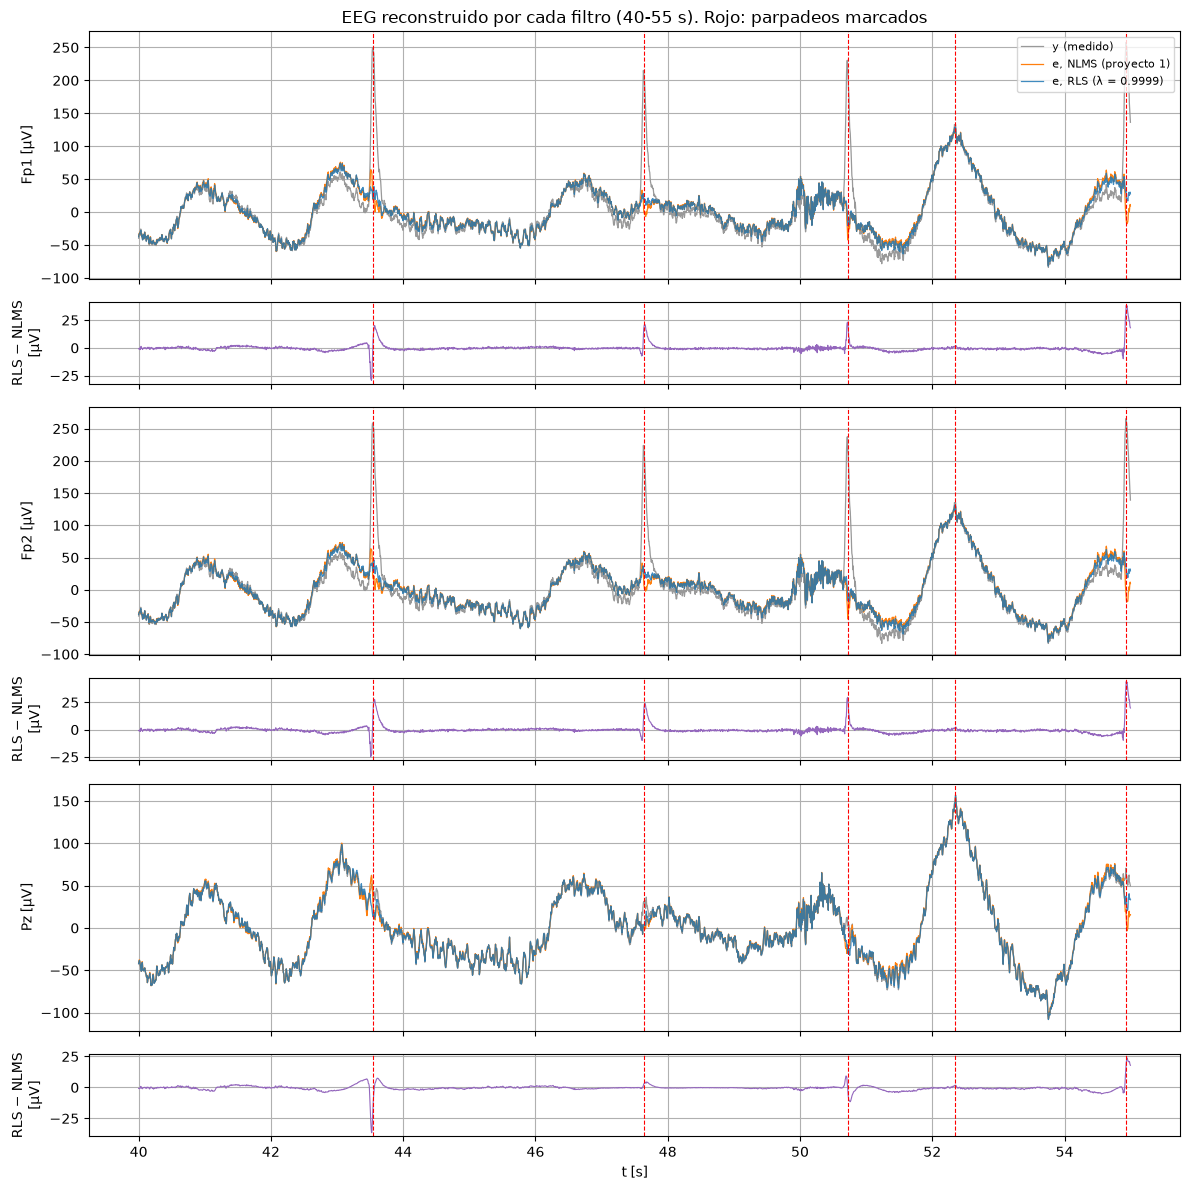

Fp1: RMS(e_RLS − e_NLMS) = 7.0 µV con parpadeo, 1.6 µV sin parpadeo  (RMS de y sin parpadeo: 22.6 µV)
Fp2: RMS(e_RLS − e_NLMS) = 7.8 µV con parpadeo, 1.6 µV sin parpadeo  (RMS de y sin parpadeo: 23.5 µV)
Pz: RMS(e_RLS − e_NLMS) = 7.2 µV con parpadeo, 1.7 µV sin parpadeo  (RMS de y sin parpadeo: 25.4 µV)


In [27]:
COLOR = {"y": "0.6", "NLMS (proyecto 1)": "tab:orange", NOMBRE_RLS: "tab:blue", "Wiener (fijo)": "k"}
i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER_3]
fig, axs = plt.subplots(2 * len(CANALES_Y), 1, figsize=(12, 12), sharex=True,
                        gridspec_kw={"height_ratios": [3, 1] * len(CANALES_Y)})
for j, canal in enumerate(CANALES_Y):
    ax, ax_d = axs[2 * j], axs[2 * j + 1]
    e_nlms, e_rls = finales[(canal, "NLMS (proyecto 1)")][0], finales[(canal, NOMBRE_RLS)][0]
    ax.plot(t[i0:i1], DATOS[canal][i0:i1], lw=0.9, color=COLOR["y"], label="y (medido)")
    ax.plot(t[i0:i1], e_nlms[i0:i1], lw=0.9, color=COLOR["NLMS (proyecto 1)"], label="e, NLMS (proyecto 1)")
    ax.plot(t[i0:i1], e_rls[i0:i1], lw=0.9, color=COLOR[NOMBRE_RLS], label=f"e, {NOMBRE_RLS}", alpha=0.85)
    ax_d.plot(t[i0:i1], (e_rls - e_nlms)[i0:i1], lw=0.8, color="tab:purple")
    for a in (ax, ax_d):
        for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
            a.axvline(t[k], color="r", lw=0.8, ls="--")
        a.grid(True)
    ax.set_ylabel(f"{canal} [µV]")
    ax_d.set_ylabel("RLS − NLMS\n[µV]")
axs[0].legend(loc="upper right", fontsize=8)
axs[0].set_title("EEG reconstruido por cada filtro (40-55 s). Rojo: parpadeos marcados")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

for canal in CANALES_Y:
    d = finales[(canal, NOMBRE_RLS)][0] - finales[(canal, "NLMS (proyecto 1)")][0]
    print(f"{canal}: RMS(e_RLS − e_NLMS) = {np.sqrt(np.mean(d[con_parpadeo]**2)):.1f} µV con parpadeo, "
          f"{np.sqrt(np.mean(d[limpio]**2)):.1f} µV sin parpadeo  (RMS de y sin parpadeo: {np.sqrt(np.mean(DATOS[canal][limpio]**2)):.1f} µV)")

### Qué mirar: las salidas en el tiempo
- **Entre parpadeos, la naranja y la azul van una encima de la otra.** La diferencia (panel violeta) es de 1.6 µV RMS fuera de los parpadeos en `Fp1`, contra 22.6 µV RMS de la señal: los dos filtros reconstruyen el mismo EEG.
- **Las diferencias están en los parpadeos** (7–8 µV RMS en las ventanas de ±0.5 s), y siempre con la misma forma: violeta **negativa justo antes del pico y positiva justo después**.
  - Negativa: NLMS deja un pico angosto en el flanco de subida del parpadeo (la naranja asoma en 43.5 y 54.9 s), que RLS no deja.
  - Positiva: después del pico, NLMS resta de más un instante.
  - **La explicación son los coeficientes.** NLMS terminaba en `w ≈ [0.20, 0.13, 0.05]`: la ganancia total está bien (0.38), pero repartida entre `HEO(n)`, `HEO(n−1)` y `HEO(n−2)`. Entonces su copia del parpadeo **llega un poco tarde**: resta poco en la subida y de más en la bajada. RLS tiene `w ≈ [0.32, 0.04, 0.03]`, el de Wiener, con casi todo en `HEO(n)`, alineado con el parpadeo.
- **Las ondas lentas (por ejemplo, 52–53 s) quedan en las dos salidas:** son la parte común, que no está en `HEO`.
- **En `Pz` las dos salidas son casi `y`.** Las diferencias, otra vez, son de un instante en cada parpadeo.

### 6.3 ¿Desaparece el parpadeo? (promedio sincronizado)
La prueba principal del proyecto 1, con las dos salidas superpuestas. Gris: `y`; naranja: NLMS; azul: RLS; negra punteada: Wiener.

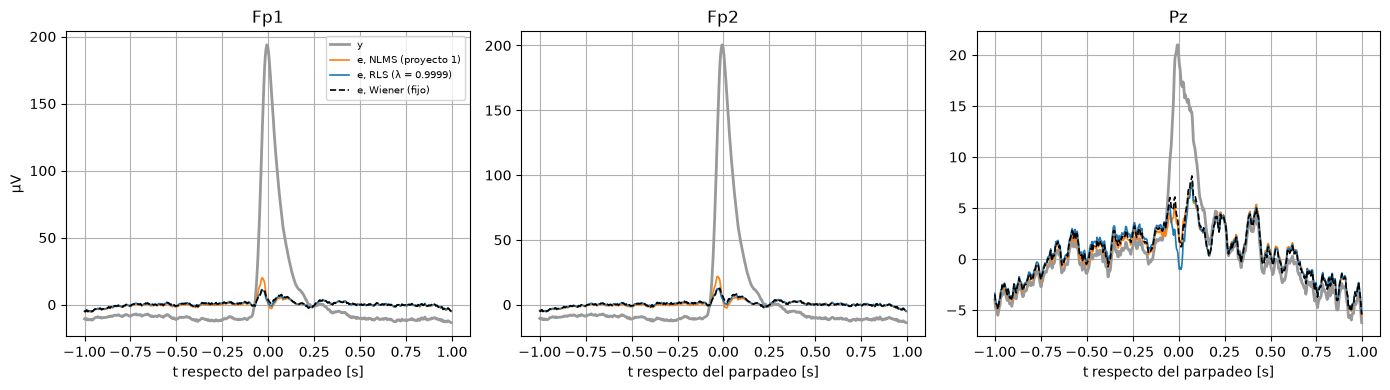

In [28]:
fig, axs = plt.subplots(1, len(CANALES_Y), figsize=(14, 4))
for ax, canal in zip(axs, CANALES_Y):
    ax.plot(tau, promedio_sincronizado(DATOS[canal], PARPADEOS), color=COLOR["y"], lw=2, label="y")
    for nombre in list(FILTROS) + ["Wiener (fijo)"]:
        ax.plot(tau, promedio_sincronizado(finales[(canal, nombre)][0], PARPADEOS), lw=1.2, label=f"e, {nombre}",
                color=COLOR[nombre], ls="--" if nombre == "Wiener (fijo)" else "-")
    ax.set_title(canal)
    ax.set_xlabel("t respecto del parpadeo [s]")
    ax.grid(True)
axs[0].set_ylabel("µV")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

Zoom de `Fp1` y `Fp2` alrededor del pico (±0.4 s), donde está lo que queda del parpadeo:

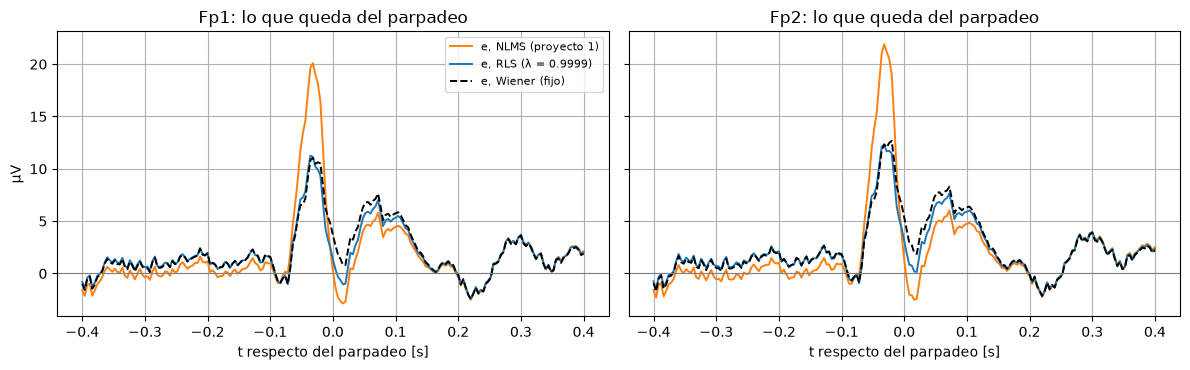

In [29]:
cerca = np.abs(tau) <= 0.4
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, canal in zip(axs, ["Fp1", "Fp2"]):
    for nombre in list(FILTROS) + ["Wiener (fijo)"]:
        ax.plot(tau[cerca], promedio_sincronizado(finales[(canal, nombre)][0], PARPADEOS)[cerca], lw=1.4,
                label=f"e, {nombre}", color=COLOR[nombre], ls="--" if nombre == "Wiener (fijo)" else "-")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"{canal}: lo que queda del parpadeo")
    ax.set_xlabel("t respecto del parpadeo [s]")
    ax.grid(True)
axs[0].set_ylabel("µV")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Qué mirar: el parpadeo promedio
- **En la escala completa, las tres curvas de `e` quedan planas** en `Fp1` y `Fp2` frente al parpadeo de ~200 µV de `y`. En `Pz`, el pico de 21 µV baja a ~8 µV con los tres.
- **En el zoom aparece la diferencia de 6.2:**
  - **NLMS** deja un pico de **+20 µV** a −0.03 s (la subida del parpadeo) y después cae a −2.5 µV en +0.01 s: llega tarde.
  - **RLS** deja **+11 µV**, encima de la curva de Wiener, y apenas baja de 0.
  - **De +0.05 s en adelante, las tres curvas coinciden,** con una joroba de +5–7 µV a los 0.07 s que deja también Wiener. Es la parte de la forma del parpadeo en `Fp1` que no es una copia escalada de la de `HEO`, y que un FIR de `M = 3` no puede copiar.

### 6.4 ¿Qué frecuencias saca cada uno?
PSD (Welch, ventanas de 2 s) de `y` y de las salidas en los tres canales, de 0 a 45 Hz. Una curva por debajo de la gris es lo que el filtro sacó.

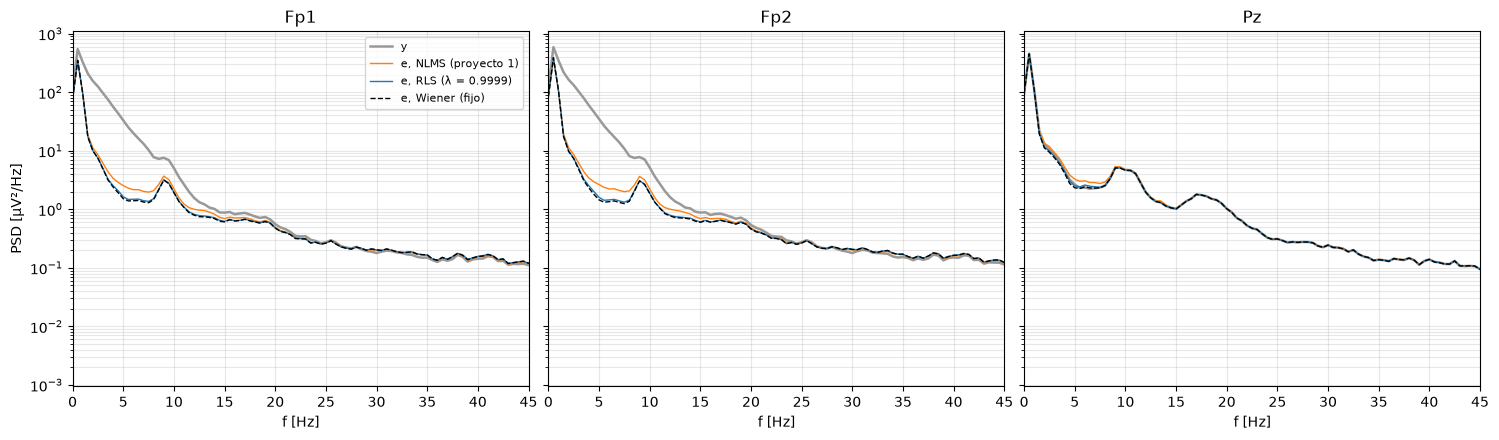

Fp1: potencia de e respecto de y por banda [dB], toda la grabación:
                   δ (0.5-4 Hz)  θ (4-8 Hz)  α (8-13 Hz)  β (13-30 Hz)
NLMS (proyecto 1)         -4.97      -10.50        -3.65         -0.60
RLS (λ = 0.9999)          -4.97      -12.08        -4.39         -0.90
Wiener (fijo)             -4.96      -12.35        -4.48         -0.95


In [30]:
fig, axs = plt.subplots(1, len(CANALES_Y), figsize=(15, 4.5), sharey=True)
for ax, canal in zip(axs, CANALES_Y):
    for nombre in ["y"] + list(FILTROS) + ["Wiener (fijo)"]:
        x = DATOS[canal] if nombre == "y" else finales[(canal, nombre)][0]
        f, P = welch(x, FS, nperseg=2 * FS)
        ax.semilogy(f, P, lw=1.8 if nombre == "y" else 1, color=COLOR[nombre],
                    label=nombre if nombre == "y" else f"e, {nombre}", ls="--" if nombre == "Wiener (fijo)" else "-")
    ax.set_xlim(0, 45)
    ax.set_title(canal)
    ax.set_xlabel("f [Hz]")
    ax.grid(True, which="both", alpha=0.3)
axs[0].set_ylabel("PSD [µV²/Hz]")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Cuánto saca cada filtro por banda, en Fp1 (en dB, toda la grabación)
BANDAS = {"δ (0.5-4 Hz)": (0.5, 4), "θ (4-8 Hz)": (4, 8), "α (8-13 Hz)": (8, 13), "β (13-30 Hz)": (13, 30)}
f, P_y = welch(DATOS["Fp1"], FS, nperseg=2 * FS)
filas = {}
for nombre in list(FILTROS) + ["Wiener (fijo)"]:
    _, P_e = welch(finales[("Fp1", nombre)][0], FS, nperseg=2 * FS)
    filas[nombre] = {b: db(P_e[(f >= lo) & (f < hi)].sum(), P_y[(f >= lo) & (f < hi)].sum()) for b, (lo, hi) in BANDAS.items()}
print("Fp1: potencia de e respecto de y por banda [dB], toda la grabación:")
print(pd.DataFrame(filas).T.round(2).to_string())

### Qué mirar: PSD
- **En `Fp1` y `Fp2`, la azul (RLS) va pegada a la negra punteada (Wiener) en todo el rango.** La naranja (NLMS) queda por encima entre ~3 y ~9 Hz (en 5 Hz, ~1.5 veces más potencia): es el resto del parpadeo de 6.3.
- **Por banda en `Fp1`** (toda la grabación, parpadeos incluidos):

  | | δ | θ | α | β |
  |---|---|---|---|---|
  | NLMS | −5.0 dB | −10.5 dB | −3.7 dB | −0.6 dB |
  | RLS | −5.0 dB | **−12.1 dB** | −4.4 dB | −0.9 dB |
  | Wiener | −5.0 dB | −12.4 dB | −4.5 dB | −1.0 dB |

  - **θ (4–8 Hz) es donde más se diferencian:** RLS saca 1.6 dB más que NLMS, y queda a 0.3 dB de Wiener.
  - **α baja −4.4 dB acá, pero −1 dB en 6.1.** La diferencia es que acá entra toda la grabación: el parpadeo es un pulso de 0.2 s y tiene potencia también en α. Lo que importa para el EEG es el −1 dB **fuera** de los parpadeos (6.1), y es igual en los tres.
- **Arriba de ~25 Hz las cuatro curvas coinciden:** ningún filtro toca β alto ni γ.
- **En `Pz` todo se superpone;** NLMS queda apenas por encima entre 3 y 7 Hz.

### 6.5 El SNR de cada filtro
**El problema:** en los datos reales no conocemos el EEG limpio, así que no se puede calcular `P_s / P(e − s)` como en el semi-sintético. Hace falta una definición que use solo lo que sí sabemos: dónde están los parpadeos.

**La definición.** Para una señal `z` (`y`, o la `e` de un filtro):
- **Ruido = el parpadeo que queda en `z`.** Es la parte de `z` atada a los parpadeos, y la estima el promedio sincronizado `z̄(τ)`: lo atado al parpadeo se suma, y el EEG tiende a 0. Su potencia en la ventana de ±0.5 s es `mean(z̄²)`. Al promedio todavía le queda algo de EEG, en promedio `P_sin / K` (con `K` = 75 parpadeos), que se resta:

  `P_parpadeo(z) = mean(z̄²) − P_sin(z) / K`

- **Señal = el EEG**, estimado con la potencia de `z` fuera de los parpadeos: `P_sin(z)`.
- **`SNR(z) = 10·log10( P_sin(z) / P_parpadeo(z) )`.** Mide cuánto parpadeo queda, comparado con el EEG, en la ventana del parpadeo.

**Qué lee cada uno:**
- `SNR(y)`: cuánto parpadeo trae el electrodo.
- `SNR(e)`: cuánto deja el filtro.
- **`ΔSNR = SNR(e) − SNR(y)`**: la mejora.

**Dos cuidados:**
1. Si `P_parpadeo` queda por debajo de lo que se puede medir (≤ 0 después de restar la parte de EEG), el parpadeo que queda no se distingue del EEG, y el SNR solo tiene una cota inferior.
2. Esta métrica premia sacar el parpadeo, pero no castiga sacar EEG: un filtro que dejara `e = 0` "mejoraría" el SNR. Por eso va junto con `RRMSE(e, y)` y α sin parpadeo de 6.1, que sí lo castigan.

La celda también da el SNR solo en 0.5–8 Hz, la banda del parpadeo.

In [31]:
VENT_SNR = np.abs(tau) <= 0.5                       # Ventana del parpadeo: ±0.5 s
K_PARP = sum(VENTANA <= k < N_MUESTRAS - VENTANA for k in PARPADEOS)   # Parpadeos que entran en el promedio


def snr_parpadeo(z):
    """
    SNR = P_sin / P_parpadeo, sin ground truth.
    P_parpadeo: potencia del promedio sincronizado en ±0.5 s, menos el EEG que queda en él (P_sin / K).
    Devuelve (SNR [dB], P_sin, P_parpadeo). Si P_parpadeo <= 0, SNR = inf (parpadeo no medible).
    """
    p_sin = np.mean(z[limpio]**2)
    p_parp = np.mean(promedio_sincronizado(z, PARPADEOS)[VENT_SNR]**2) - p_sin / K_PARP
    return (10 * np.log10(p_sin / p_parp) if p_parp > 0 else np.inf), p_sin, p_parp


filas = {}
for canal in CANALES_Y:
    y = DATOS[canal]
    y_08 = sosfiltfilt(sos_08, y)
    snr_y, snr_y08 = snr_parpadeo(y)[0], snr_parpadeo(y_08)[0]
    filas[(canal, "y (sin filtrar)")] = {"SNR [dB]": snr_y, "ΔSNR [dB]": 0.0, "SNR 0.5-8 Hz [dB]": snr_y08,
                                         "ΔSNR 0.5-8 Hz [dB]": 0.0, "P_sin [µV²]": snr_parpadeo(y)[1],
                                         "P_parpadeo [µV²]": snr_parpadeo(y)[2]}
    for nombre in list(FILTROS) + ["Wiener (fijo)"]:
        e = finales[(canal, nombre)][0]
        snr_e, p_sin, p_parp = snr_parpadeo(e)
        snr_e08 = snr_parpadeo(sosfiltfilt(sos_08, e))[0]
        filas[(canal, nombre)] = {"SNR [dB]": snr_e, "ΔSNR [dB]": snr_e - snr_y, "SNR 0.5-8 Hz [dB]": snr_e08,
                                  "ΔSNR 0.5-8 Hz [dB]": snr_e08 - snr_y08, "P_sin [µV²]": p_sin, "P_parpadeo [µV²]": p_parp}
tabla_snr = pd.DataFrame(filas).T
tabla_snr.index.names = ["canal", "señal"]
print(tabla_snr.round(1).to_string())
print(f"\nK = {K_PARP} parpadeos. Ventana de ±0.5 s alrededor de cada marca.")

                         SNR [dB]  ΔSNR [dB]  SNR 0.5-8 Hz [dB]  ΔSNR 0.5-8 Hz [dB]  P_sin [µV²]  P_parpadeo [µV²]
canal señal                                                                                                       
Fp1   y (sin filtrar)        -7.1        0.0              -12.7                 0.0        509.5            2588.2
      NLMS (proyecto 1)      17.4       24.5               12.6                25.4        473.8               8.5
      RLS (λ = 0.9999)       25.4       32.4               19.1                31.9        483.9               1.4
      Wiener (fijo)          23.0       30.1               16.8                29.6        483.0               2.4
Fp2   y (sin filtrar)        -7.0        0.0              -12.7                 0.0        554.4            2762.0
      NLMS (proyecto 1)      16.8       23.8               12.0                24.7        521.2              10.8
      RLS (λ = 0.9999)       22.4       29.4               17.5                3

El SNR en un gráfico de barras, para comparar de un vistazo:

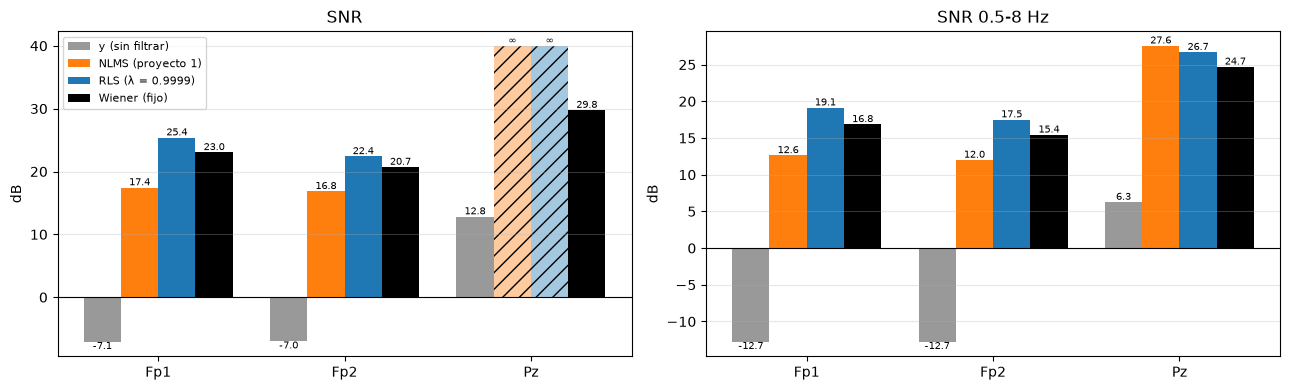

In [32]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
senales = ["y (sin filtrar)"] + list(FILTROS) + ["Wiener (fijo)"]
colores_b = [COLOR["y"], COLOR["NLMS (proyecto 1)"], COLOR[NOMBRE_RLS], "k"]
ancho = 0.2
for ax, col in zip(axs, ["SNR [dB]", "SNR 0.5-8 Hz [dB]"]):
    for j, (s, c) in enumerate(zip(senales, colores_b)):
        vals = [tabla_snr.loc[(canal, s), col] for canal in CANALES_Y]
        alto = [v if np.isfinite(v) else 40 for v in vals]             # inf (parpadeo no medible): barra hasta 40 dB, rayada
        barras = ax.bar(np.arange(len(CANALES_Y)) + (j - 1.5) * ancho, alto, ancho, color=c, label=s)
        for b, v in zip(barras, vals):
            if not np.isfinite(v):
                b.set_hatch("//"); b.set_alpha(0.4)
        ax.bar_label(barras, labels=[f"{v:.1f}" if np.isfinite(v) else "∞" for v in vals], fontsize=7)
    ax.set_xticks(np.arange(len(CANALES_Y)), CANALES_Y)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("dB")
    ax.set_title(col.replace(" [dB]", ""))
    ax.grid(True, axis="y", alpha=0.3)
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Qué mirar: el SNR
- **En `Fp1`, el electrodo trae un SNR de −7.1 dB:** en la ventana del parpadeo hay 5 veces más potencia de parpadeo (2588 µV²) que de EEG (510 µV²).

  | SNR [dB] | `Fp1` | `Fp2` | `Pz` |
  |---|---|---|---|
  | `y` (sin filtrar) | −7.1 | −7.0 | 12.8 |
  | NLMS (proyecto 1) | 17.4 (**+24.5**) | 16.8 (**+23.8**) | ∞ (no medible) |
  | **RLS** | **25.4 (+32.4)** | **22.4 (+29.4)** | ∞ (no medible) |
  | Wiener (no causal) | 23.0 (+30.1) | 20.7 (+27.7) | 29.8 (+16.9) |

  Entre paréntesis, `ΔSNR`. En la banda 0.5–8 Hz el orden es el mismo: en `Fp1` pasa de −12.7 dB a 12.6 (NLMS), **19.1 (RLS)** y 16.8 dB (Wiener).
- **RLS mejora el SNR ~8 dB más que NLMS en `Fp1` y ~6 dB más en `Fp2`.** La potencia del parpadeo que queda baja de 8.5 µV² (NLMS) a 1.4 µV² (RLS) en `Fp1`.
- **Coincide con el semi-sintético,** donde el SNR sí se calcula contra el EEG verdadero: 19.9 dB (RLS) contra 14.0 dB (NLMS), +5.9 dB (§5.4). Dos medidas independientes dan la misma diferencia, de 6–8 dB.
- **La mejora no viene de sacar EEG:** `P_sin` baja de 510 a 474–484 µV² con los tres filtros (−5 a −7 %, el −1 dB de α de 6.1). Lo que cambia entre filtros es cuánto parpadeo dejan, no cuánto EEG.
- **RLS y Wiener empatan** (25.4 contra 23.0 dB en `Fp1`; ver el cuidado que sigue).
- **Ojo con la precisión de los SNR más altos:** a esos niveles, `P_parpadeo` es de 1.4–2.4 µV², y la corrección por el EEG que queda en el promedio (`P_sin / K` ≈ 6.4 µV²) es más grande que eso. Por eso el `∞` en `Pz` quiere decir "por debajo de lo que se puede medir". **Lo firme es el orden: RLS ≈ Wiener > NLMS, con 6–8 dB entre RLS y NLMS.** Las décimas no hay que leerlas.

### 6.6 En tiempo real: parpadeo por parpadeo desde el arranque
En una implementación real no hay "segunda mitad": el filtro tiene que andar desde que se prende. Para cada uno de los 75 parpadeos, la celda mide **cuánto parpadeo queda en `e`**: el valor de `e` en el pico de `y` (dentro de ±0.1 s de la marca), menos la mediana de `e` entre −1 y −0.5 s (el nivel de base). Es la tabla parpadeo por parpadeo del proyecto 1, ahora para los 75 y en el tiempo.

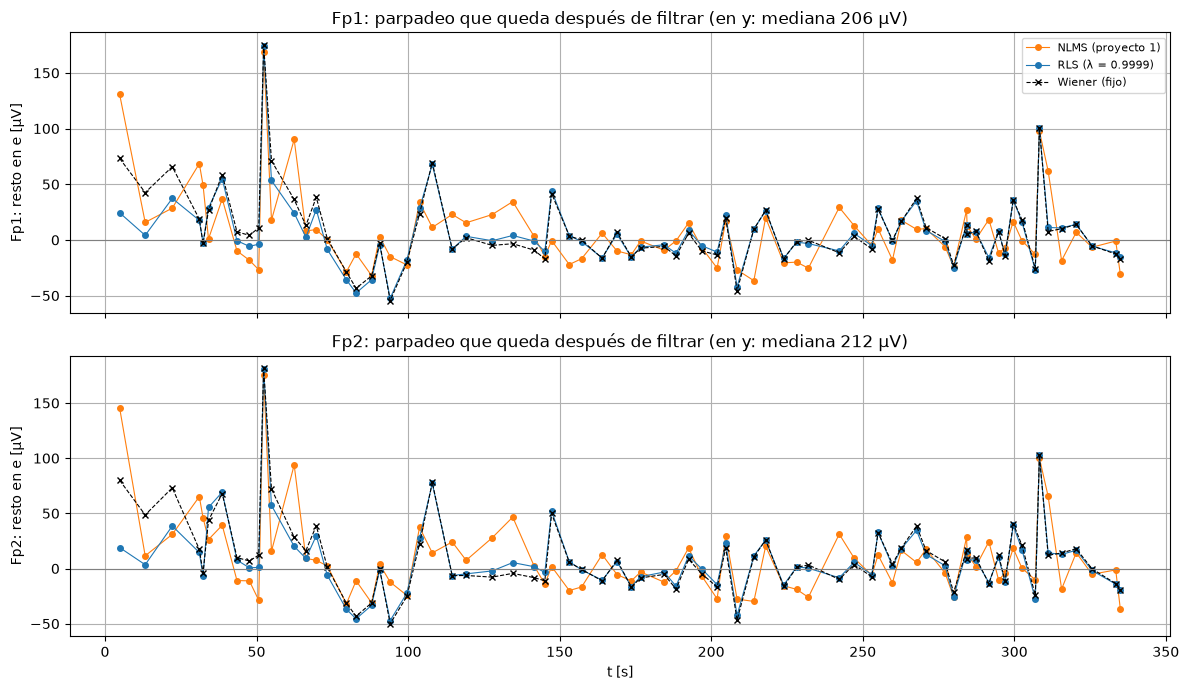

                                         mediana |resto| [µV]  máx |resto| [µV]  parpadeos
canal filtro            tramo                                                             
Fp1   NLMS (proyecto 1) primeros 30 s                    48.5             130.7        4.0
                        después de 30 s                  15.4             168.6       71.0
      RLS (λ = 0.9999)  primeros 30 s                    21.0              37.3        4.0
                        después de 30 s                  11.2             173.8       71.0
      Wiener (fijo)     primeros 30 s                    54.2              73.2        4.0
                        después de 30 s                  13.1             175.0       71.0
Fp2   NLMS (proyecto 1) primeros 30 s                    48.1             145.5        4.0
                        después de 30 s                  15.6             175.5       71.0
      RLS (λ = 0.9999)  primeros 30 s                    16.8              38.6        4.0

In [33]:
def resto_por_parpadeo(y, e):
    """Para cada parpadeo: e en el pico de y (±0.1 s de la marca), respecto del nivel de base de e en [-1, -0.5] s."""
    filas = []
    for k in PARPADEOS:
        if not VENTANA <= k < N_MUESTRAS - VENTANA:
            continue
        kp = k - FS // 10 + np.argmax(y[k - FS // 10:k + FS // 10])          # Pico de y cerca de la marca
        base_y, base_e = np.median(y[k - VENTANA:k - VENTANA // 2]), np.median(e[k - VENTANA:k - VENTANA // 2])
        filas.append({"t [s]": t[kp], "parpadeo en y [µV]": y[kp] - base_y, "resto en e [µV]": e[kp] - base_e})
    return pd.DataFrame(filas)


fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
resumen = {}
for ax, canal in zip(axs, ["Fp1", "Fp2"]):
    for nombre in list(FILTROS) + ["Wiener (fijo)"]:
        r = resto_por_parpadeo(DATOS[canal], finales[(canal, nombre)][0])
        ax.plot(r["t [s]"], r["resto en e [µV]"], "o-" if nombre != "Wiener (fijo)" else "x--", ms=4, lw=0.8,
                color=COLOR[nombre], label=nombre)
        for tramo, sel in [("primeros 30 s", r["t [s]"] < T_INI + 30), ("después de 30 s", r["t [s]"] >= T_INI + 30)]:
            resumen[(canal, nombre, tramo)] = {"mediana |resto| [µV]": r.loc[sel, "resto en e [µV]"].abs().median(),
                                               "máx |resto| [µV]": r.loc[sel, "resto en e [µV]"].abs().max(),
                                               "parpadeos": int(sel.sum())}
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_ylabel(f"{canal}: resto en e [µV]")
    ax.grid(True)
    ax.set_title(f"{canal}: parpadeo que queda después de filtrar (en y: mediana "
                 f"{r['parpadeo en y [µV]'].median():.0f} µV)")
axs[0].legend(fontsize=8)
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

tabla_rt = pd.DataFrame(resumen).T
tabla_rt.index.names = ["canal", "filtro", "tramo"]
print(tabla_rt.round(1).to_string())

### Qué mirar: parpadeo por parpadeo
- **El arranque es la diferencia más clara para una implementación real:**

  | Mediana de \|resto\| [µV] | primeros 30 s (4 parpadeos) | después de 30 s (71) |
  |---|---|---|
  | `Fp1`: NLMS | 48.5 | 15.4 |
  | `Fp1`: **RLS** | **21.0** | **11.2** |
  | `Fp1`: Wiener (no causal) | 54.2 | 13.1 |
  | `Fp2`: NLMS | 48.1 | 15.6 |
  | `Fp2`: **RLS** | **16.8** | **12.8** |
  | `Fp2`: Wiener (no causal) | 60.9 | 13.7 |

  - **En el primer parpadeo (5 s), NLMS deja 131 µV en `Fp1` (de ~200) y RLS ~24 µV.** NLMS tarda ~30 s (4–6 parpadeos) en limpiar bien. RLS limpia desde el primero, porque su convergencia no depende del spread (§3, chequeo (b)).
  - **En el arranque, Wiener queda peor que RLS.** Una pista, con solo 4 parpadeos: la ganancia de Wiener calculada con los primeros 30 s es 0.40–0.42, y con el resto de la grabación, 0.385. Al principio RLS tiene pocos datos y ajusta a los locales; Wiener aplica la ganancia promedio.
- **Después de ~100 s, RLS y Wiener coinciden parpadeo por parpadeo.** NLMS se desvía ±20–30 µV alrededor de ellos (por ejemplo, 115–145 s y 240–250 s).
- **Dos puntos que no son del filtro: 52.3 s (~175 µV) y 308 s (~100 µV).** Dan lo mismo con los tres filtros, Wiener incluido. En 52.3 s, lo que hay en `y` en la marca es la onda lenta común, no un parpadeo (ya lo habíamos visto en el proyecto 1). Por eso la tabla usa la mediana.

## §7. Conclusiones

### Sobre los datos crudos, como se usaría en la práctica, RLS reconstruye el EEG mejor que el NLMS del proyecto 1, y tan bien como el mejor filtro fijo

**El filtro:** RLS convencional, `x` = `HEO`, `M = 3`, `λ = 0.9999`, `δ = 100·σx²`.

| | NLMS (proyecto 1) | **RLS** | Wiener (no causal) |
|---|---|---|---|
| **Semi-sintético:** `RRMSE(e, s)` (sin filtrar: 1.23) | 0.205 | **0.104** | 0.096 |
| **Semi-sintético:** SNR de salida (sin filtrar: −1.8 dB) | 14.0 dB | **19.9 dB** | — |
| **Datos reales:** SNR en `Fp1` (sin filtrar: −7.1 dB) | 17.4 dB | **25.4 dB** | 23.0 dB |
| Parpadeo promedio que queda en `Fp1` (de 203 µV) | +21.6 µV | **+12.3 µV** | +12.1 µV |
| Resto en los primeros 30 s (mediana, `Fp1`) | 48.5 µV | **21.0 µV** | 54.2 µV |
| α fuera de los parpadeos | −1.0 dB | −1.0 dB | −1.0 dB |
| `Pz` (control): `RRMSE(e, y)` | 0.07 | **0.04** | 0.03 |

**1. Cómo se eligieron los parámetros.**
- **`λ = 0.9999`**: primero por razonamiento (§2: la memoria de 40 s abarca ~9 parpadeos, y con menos memoria la potencia de `HEO` que ve RLS cae 275 veces entre parpadeos). Después lo confirmó el semi-sintético (§5): el error baja hasta 0.9999 y ahí se satura; `λ = 1` mejora 1.6 %, no significativo.
- **`δ = 100·σx²`**: lo eligió el semi-sintético (§5.3): −26 % de error en los primeros 10 s, sin costo en régimen.
- **`M = 3`**: de 2 a 8 da lo mismo (§5.5).

**2. `λ` cumple el papel que tenía `δ` en NLMS** (§2, §4). Con `λ = 0.99`, RLS falla como NLMS con `δ` chico: pasos enormes entre parpadeos, coeficientes que saltan, ruido agregado (también en el control).

**3. Los dos filtros reconstruyen el mismo EEG fuera de los parpadeos** (§6.2). La diferencia entre sus salidas es de 1.6 µV RMS, contra ~23 µV RMS de EEG. Los dos preservan el EEG igual que Wiener: α −1 dB, `RRMSE` 0.31–0.32, el control intacto. Ese −1 dB también lo hace Wiener, así que viene de los datos y no se le puede atribuir a ningún algoritmo.

**4. En los parpadeos, RLS saca más:** deja la mitad de resto que NLMS, mejora el SNR ~8 dB más en `Fp1` y ~6 dB más en `Fp2`, y saca 1.6 dB más de θ. **El semi-sintético, con el EEG verdadero, da la misma diferencia** (+5.9 dB de SNR de salida, `RRMSE` a la mitad, 30 de 30 mezclas).

**5. Por qué: RLS llega a cada coeficiente, NLMS y LMS solo a su suma.** Los dos aprenden la ganancia total (~0.39). Pero NLMS la reparte mal entre `HEO(n)`, `HEO(n−1)` y `HEO(n−2)`, y su copia del parpadeo llega tarde: deja un pico en la subida y resta de más en la bajada (§6.2, §6.3). Es el spread de 2685, que frena a LMS/NLMS y no a RLS (§3, chequeo (b); §5.4).

**6. RLS contra LMS en condiciones parecidas** (§5.4): con el mismo desajuste teórico (`μ̃ = 3·10⁻⁴`), **RLS llega al piso de Wiener en ~8 s y LMS en ~25 s, y LMS queda por encima** (`RRMSE` 0.145 contra 0.104). Es el resultado de libro, y se cumple con estos datos.

**7. En tiempo real, RLS anda desde el primer parpadeo** (~24 µV de resto a los 5 s, contra 131 µV de NLMS). NLMS necesita ~30 s.

**8. El costo no es un problema.** Con `M = 3`, RLS hace ~30 multiplicaciones por muestra (actualizar `P` es O(M²)), contra ~10 de NLMS. A 250 Hz son ~7500 por segundo. En 336 s no hubo problemas numéricos: `α(n)` siempre en (0, 1] y `P` definida positiva (§3, chequeo (c)).

### Lo que esto no prueba
- **El SNR de los datos reales es una definición nuestra, sin ground truth:** mide cuánto parpadeo queda, no si se sacó EEG. Por eso va junto con α y `RRMSE`. Los SNR más altos (> 20 dB) están cerca del piso de medición: vale el orden, no las décimas. Lo respalda que el semi-sintético da la misma diferencia.
- **El `δ` elegido no se nota en los datos reales:** el resto de parpadeo es +12.3 µV con `δ = 100·σx²` y +9.7 µV con el de libro, cerca de lo que estas pruebas distinguen. Lo elegimos por el semi-sintético, que sí conoce la respuesta.
- **El −1 dB de α** fuera de los parpadeos lo hacen los tres filtros: puede ser EEG frontal que también ve `HEO` (lo estaríamos sacando) o movimientos chicos de ojos (ruido bien sacado). Sin ground truth no se separa.
- **Un sujeto, una sesión.** La parte común lenta (0.5–3 Hz) no está en `HEO`, y ningún filtro con esta referencia la puede sacar.